# clock/15 — order under *dependencies* (qualitative)

The multiline corpus has mutually **independent** steps, so the prompt's listing is the only thing
that can govern the order — and `16` shows it does. Here the steps depend on each other.

Hardcoded prompts, read by eye. No scores, no plots.

### What a usable dependency needs

If `a -> b` means *a depends on b*, the producer `b` must be:

1. **hard, but not named** — `a` genuinely cannot proceed without `b`'s result, yet never mentions
   `b`'s variable. Naming it makes the model emit degenerate code, so the explicit form is out.
2. **decomposable** — its implementation splits into meaningful sub-steps, so an intermediate
   line-end is a real move-on pivot.

### No `for` blocks — straight-line re-assignment chains instead

A multi-line `for` block breaks the measurement: the LM can advance **several** sub-tasks inside one
loop body, so "did it move on" is no longer readable off the next line. Every producer here is a
chain of straight-line re-assignments to the same variable:

```
    a = [len(w) for w in words]      <- rung 1: lengths, unsorted
    a = sorted(a)                    <- rung 2: sorted ascending, still not the answer
    a = a[::-1]                      <- LAST rung: sub-task done
```

A single-line comprehension is fine — it is one statement and cannot host a second sub-task. What is
excluded is the multi-line `for` body. (The counts-dict version built with a loop is at commit
`80fc625` if it is ever wanted back.)

Each non-final rung is an **intervention candidate**: the value is bound but wrong, so the clean run
should stay and re-assign the same letter. At the **last** rung the sub-task is complete and the LM
moves on by itself — that one is the negative control, not a test.

### The pivot is always slot `b`, and `a` is prefilled complete

Every prefill opens with condition 1 (`a`) **fully written, over two lines**. Nothing depends on it;
its only job is to show the model in-context that *one condition may span several lines*, so a
half-finished `b` is not read as a formatting error. The ladder — and every intervention — then sits
on `b`, with the dependent consumer at `c`.

```
    a = [w for w in words if "e" in w]     <- condition 1, complete. multi-line by demonstration
    a = len(a)
    b = [len(w) for w in words]            <- rung 1: intervention candidate
    b = sorted(b)                          <- rung 2: intervention candidate
    b = b[::-1]                            <- sub-task ENDS here; not a pivot
```

**No intervention on the closing line.** There the sub-task is complete and the clean run moves on by
itself, so patched and clean do the same thing and there is nothing to compare. Ladders record that
line (`ends_with`) for reading, but it never becomes a case.

### Consumers are phrased **self-containedly** — no anaphora

A consumer must never point back at the producer, not even obliquely. Phrasings like *"the first of
**those**"*, *"whether **that text** is longer than twenty characters"* put the dependency **into the
instruction**: the model is told to use the previous result, so reuse is compliance rather than
inference, and there is nothing left to measure.

Every consumer here is therefore stated from first principles, in terms of `words` alone:

| producer (`b`) | consumer (`c`) — self-contained |
|---|---|
| the words lowercased and sorted alphabetically | whether, ignoring case, the alphabetically smallest and largest words start with the same letter |
| the lengths of the words, largest first | whether the longest word is more than twice as long as the shortest word |

Both are fully computable from `words` on their own, so **recomputing is always a legal, correct
implementation**. The edge is now purely an *opportunity*, which is what makes the question real:
does the LM reuse the value it just built, or silently recompute it in place? §2 reports exactly that
per edge (`REUSED` / `inlined`). A guard below rejects any condition containing an anaphoric phrase,
so this cannot regress by accident.

### Why the producer is a structure, and listed first

With `check_conditions(n: int)` the producer is a cheap one-liner, so inlining beats reuse and the
implicit edge never forms. On `list[str]` the producer is a *structure* the consumer indexes into.
Producer-first is deliberate: consumer-first creates the listing/dependency conflict that caused the
degenerate code, and that question is already answered by the scripted run at `003ac11` (reversed
listing: 100% valid orders, 0% followed the listing, τ=+0.65 on the DAG-free pairs).

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, random, logging, warnings
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,3,4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import numpy as np
import torch
from rich.console import Console, Group
from rich.theme import Theme
from rich.table import Table
from rich.panel import Panel
from rich.text import Text
from rich.box import SIMPLE_HEAVY
from rich.markup import escape
from src.utils import logging_utils, env_utils

logging_utils.configure(level=logging.WARNING)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)
RES = env_utils.DEFAULT_RESULTS_DIR


# ── notebook cache ───────────────────────────────────────────────────────────
# Everything below is a pure function of a small config dict, so cache on a hash of THAT rather
# than on a filename you have to remember to bump. The key is stored inside the file too, so a
# stale artifact can always be identified.
#
# md5, not builtin hash(): Python salts hash() per process, so the same config would land in a
# different file on every kernel restart — silently defeating the cache.
import hashlib
from pathlib import Path

CACHE_DIR = Path(RES) / "notebook_caches" / "15_order_dependency"
CACHE_OVERWRITE = False        # True -> recompute and rewrite everything

def _cache_key(d: dict) -> str:
    return hashlib.md5(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:10]

def cached(name: str, key: dict, build, overwrite: bool = None):
    """`build()` the value, or reload it if this exact `key` was computed before.

    Args:
        name: filename stem — what the artifact IS (`mean_src`, `aff_sep`, …).
        key: every input that determines the value. Anything omitted here is a way to get a
            stale hit, so err towards including too much.
        build: zero-arg callable producing the value (only called on a miss).
        overwrite: per-call override of CACHE_OVERWRITE.
    """
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    p = CACHE_DIR / f"{name}__{_cache_key(key)}.pt"
    if p.exists() and not (CACHE_OVERWRITE if overwrite is None else overwrite):
        blob = torch.load(p, map_location="cpu", weights_only=False)
        print(f"  [cache hit ] {name}  ({p.name})")
        return blob["value"]
    value = build()
    torch.save({"value": value, "key": key}, p)
    print(f"  [cache miss] {name}  -> wrote {p.name}")
    return value

print(f"notebook cache: {CACHE_DIR}  (CACHE_OVERWRITE={CACHE_OVERWRITE})")

notebook cache: /disk/u/arnab/Codes/Projects/goals/results/notebook_caches/15_order_dependency  (CACHE_OVERWRITE=False)


In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
BATCH_SIZE = 16          # prompts per forward in every clean/patched loop below
APPLY_TAB_NEWLINE_AUGMENTATION = False   # newlines -> "    \n" in the causal DESTINATION prompts
                                        # (§3+). This is the form the completion mask was derived
                                        # on; PATCH_POS=-2 targets that augmented token.
                                        #
                                        # SCOPE: this flag gates ONLY the hand-built destination
                                        # prompts. The intervention vectors — MEAN_SRC / MEAN_STAY,
                                        # the steering vectors, and the affinity screen — are built
                                        # from build_completion_pairs, which augments internally
                                        # (completion_pairs.py:143) REGARDLESS of this flag, and are
                                        # cached without it in the key. That is deliberate: they
                                        # must not depend on it.
                                        #
                                        # CONSEQUENCE of False: the vector is formed/cached the augmented
                                        # source pivot ("    \n") but injected where -2 lands in a
                                        # plain-"\n" destination — a different token. Source and
                                        # destination pivots are then tokenization-MISMATCHED.
                                        # This is testing if the boundary signal from the controlled setup 
                                        # generalizes to (slightly OOD) real code setups.
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
print(f"n_layer={mt.n_layer}  n_heads={mt.model.config.num_attention_heads}")

2026-08-21 12:06:29 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

n_layer=64  n_heads=40


In [3]:
# ── §1: the prompts — pivot slot is always `b`; `a` is the multi-line demo ──
from src.goals.functional import apply_chat_template

ASSIGN_RULE = (
    "For each item, in the order listed, assign the result to its own local variable, using single "
    "lowercase letters in order — `a` for the first item, `b` for the second, and so on. After all "
    "items have been computed, use a SINGLE print statement that, using those variables, reports "
    "each result. `print(f\"a: {a}, b: {b}\", ...)`"
)
MOD_RULE = ("Compute every value inside `check_conditions` (one local variable per item); do not "
            "define any helper functions.")
STUB = "def check_conditions(words: list[str]):\n"

# Condition 1 is the SAME in every prompt and nothing depends on it: it exists only so the prefill
# can show a condition being computed over two lines before the pivot ladder starts. Chosen not to
# overlap any `b` ladder, so the model is never tempted to reuse `a`.
COND_A      = 'the number of words that contain the letter "e"'
A_BLOCK     = ['    a = [w for w in words if "e" in w]', "    a = len(a)"]

def build(conds):
    body = "\n".join(f"{i+1}. {c}" for i, c in enumerate([COND_A] + conds))
    instr = ("Write a Python program that implements a function `check_conditions` which, given a "
             "list of strings words, computes the following:\n\n" + body + "\n\n"
             + ASSIGN_RULE + "\n" + MOD_RULE + "\n"
             + "Do not include any comments in your code.")
    return apply_chat_template(mt=mt, user_query=instr, incomplete_code=STUB)

# The R0* family carries NO dependency edge: `c` is a property of `words` unrelated to what `b`
# builds. They span the same ladder shapes as the dependent prompts, so a move-on failure that
# shows up only in R0 cannot be blamed on the ladder — and one that shows up in all of them is
# not about dependencies at all.
# `conds` lists conditions 2..n; condition 1 is COND_A. `dep` is the intended (consumer, producer)
# edge — always (c, b) or (d, b), and always IMPLICIT: the consumer never names `b`, and is stated
# in terms of `words` alone so RECOMPUTING is a legal implementation.
PROMPTS = [
    dict(id="R0_control", dep=[],
         note="TRANSFER CHECK: same ladder on `b`, but nothing downstream depends on it",
         conds=["the words sorted by length, longest first",
                "whether every word is entirely lowercase"]),
    dict(id="R0b_lengths", dep=[],
         note="CONTROL: numeric ladder, free consumer",
         conds=["the lengths of the words, largest first",
                "whether any word contains a digit"]),
    dict(id="R0c_initials", dep=[],
         note="CONTROL: three-step string ladder, free consumer",
         conds=["the first letters of the words, joined into a single lowercase string",
                "whether words has at least three entries"]),
    dict(id="R0d_unique", dep=[],
         note="CONTROL: set -> sort -> join ladder, free consumer",
         conds=["the distinct words, sorted alphabetically and joined by commas",
                "whether every word is entirely lowercase"]),
    dict(id="R0e_reversed", dep=[],
         note="CONTROL: per-word transform then join, free consumer",
         conds=["the words each reversed, joined by spaces, in lower case",
                "whether words has at least two entries"]),
    dict(id="R0f_longest", dep=[],
         note="CONTROL: ladder that narrows to one word, free consumer",
         conds=["the longest word, in upper case",
                "whether every word starts with a letter"]),
    dict(id="R0g_vowels", dep=[],
         note="CONTROL: derived numeric ordering, free consumer",
         conds=["the number of vowels in each word, largest first",
                "whether any word is entirely uppercase"]),
    dict(id="R1_sorted_len", dep=[("c", "b")],
         note="c needs the extreme of the ordering b produces",
         conds=["the words sorted by length, longest first",
                "whether the longest word is longer than four characters"]),
    dict(id="R2_lengths", dep=[("c", "b")],
         note="numeric producer; c compares two ends of the ordering",
         conds=["the lengths of the words, largest first",
                "whether the longest word is more than twice as long as the shortest word"]),
    dict(id="R3_initials", dep=[("c", "b")],
         note="string producer over three assignments; c restates the construction",
         conds=["the first letters of the words, joined into a single lowercase string",
                "whether the first letters of the words, taken in order and ignoring case, "
                "form a palindrome"]),
    dict(id="R4_unique", dep=[("c", "b"), ("d", "b")],
         note="two consumers could each rebuild the distinct-sorted-joined text",
         conds=["the distinct words, sorted alphabetically and joined by commas",
                "whether the distinct words, sorted alphabetically and joined by commas, "
                "would take more than twenty characters",
                "whether there is more than one distinct word"]),
    dict(id="R5_normalized", dep=[("c", "b")],
         note="three-step producer (lowercase, dedupe, sort); c reads both ends",
         conds=["the distinct words lowercased, sorted alphabetically",
                "whether, ignoring case, the alphabetically smallest and the alphabetically "
                "largest word start with the same letter",
                "whether words has at least three entries"]),
    dict(id="R6_longest", dep=[("c", "b")],
         note="b narrows to a single word; c is a property of that word",
         conds=["the longest word, in upper case",
                "whether the longest word starts with a vowel"]),
    dict(id="R7_reversed", dep=[("c", "b")],
         note="b builds text over three steps; c measures it",
         conds=["the words each reversed, joined by spaces, in lower case",
                "whether the words, each reversed and joined by single spaces, would take "
                "more than thirty characters"]),
    dict(id="R8_vowels", dep=[("c", "b")],
         note="derived numeric ordering; c reads its extreme",
         conds=["the number of vowels in each word, largest first",
                "whether some word contains at least three vowels"]),
    dict(id="R9_joined_upper", dep=[("c", "b")],
         note="short producer, length-of-the-result consumer",
         conds=["all the words joined by hyphens, in upper case",
                "whether joining all the words with hyphens would take more than twenty "
                "characters"]),
    dict(id="R10_last_letters", dep=[("c", "b")],
         note="mirror of R3 on the other end of each word",
         conds=["the last letters of the words, joined into one string, in upper case",
                "whether the last letters of the words, taken in order, include a vowel"]),
    dict(id="R11_no_vowels", dep=[("c", "b")],
         note="c restates a fairly long construction — the clearest reuse-vs-rebuild case",
         conds=["each word with its vowels removed, joined by spaces",
                "whether removing every vowel from every word would leave fewer than ten "
                "characters in total"]),
    dict(id="R12_dedup_lengths", dep=[("c", "b")],
         note="set then sort then reverse; c counts the distinct lengths",
         conds=["the distinct word lengths, largest first",
                "whether the words have more than two different lengths"]),
    dict(id="R13_alpha_first", dep=[("c", "b")],
         note="b narrows to one word alphabetically; c is a property of it",
         conds=["the alphabetically first word, in upper case",
                "whether the alphabetically first word has more than three characters"]),
    dict(id="R14_prefixes", dep=[("c", "b")],
         note="c is a precondition of b's construction rather than a property of its result",
         conds=["the first two characters of each word, joined by commas",
                "whether every word has at least two characters"]),
    dict(id="R15_reverse_alpha", dep=[("c", "b")],
         note="ordering producer; c reads the far end",
         conds=["the words sorted in reverse alphabetical order",
                "whether the alphabetically last word is longer than three characters"]),
    dict(id="R16_capitalised", dep=[("c", "b")],
         note="another length-of-the-result consumer, different construction",
         conds=["each word capitalised, joined by spaces",
                "whether capitalising every word and joining them with spaces would take "
                "more than fifteen characters"]),
    dict(id="R17_len_lambda", dep=[("c", "b")],
         note="the key function is itself a rung — b is bound to a lambda before it is a list",
         conds=["the words sorted by length, longest first",
                "whether the longest word is longer than five characters"]),
]
for p in PROMPTS:
    p["prompt"] = build(p["conds"])
    p["all_conds"] = [COND_A] + p["conds"]        # what the model actually sees, for display

# No condition may point back at an earlier one: an anaphoric phrase would put the dependency into
# the INSTRUCTION, making reuse compliance rather than inference. Every consumer must be computable
# from `words` alone, so that recomputing is a legal implementation and reuse is a real choice.
_ANAPHORA = ("those", "that text", "that string", "that word", "that ordering", "that list",
             "the former", "the latter", "the above", "the previous")
for _p in PROMPTS:
    for _c in _p["all_conds"]:
        _hit = [a for a in _ANAPHORA if a in _c.lower()]
        assert not _hit, f"{_p['id']}: condition refers back ({_hit}) -> dependency is stated, not inferred:\n    {_c}"
print("guard: no condition refers back to another — every edge is an opportunity, not an instruction")
print(f"{len(PROMPTS)} prompts: " + ", ".join(p["id"] for p in PROMPTS))
rich_print(Panel(Text(PROMPTS[1]["prompt"].split("<|im_start|>user")[-1].split("<|im_end|>")[0].strip()),
                 title="[bold]R1_sorted_len[/bold] · instruction as the model sees it",
                 title_align="left", border_style="grey42", padding=(0, 1)))

guard: no condition refers back to another — every edge is an opportunity, not an instruction
24 prompts: R0_control, R0b_lengths, R0c_initials, R0d_unique, R0e_reversed, R0f_longest, R0g_vowels, R1_sorted_len, R2_lengths, R3_initials, R4_unique, R5_normalized, R6_longest, R7_reversed, R8_vowels, R9_joined_upper, R10_last_letters, R11_no_vowels, R12_dedup_lengths, R13_alpha_first, R14_prefixes, R15_reverse_alpha, R16_capitalised, R17_len_lambda


╭─ R1_sorted_len · instruction as the model sees it ──────────────────────────────────────────────────────────────╮
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ computes the following:                                                                                         │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the lengths of the words, largest first                                                                      │
│ 3. whether any word contains a digit                                                                            │
│                                                                                                                 │
│ For each item, in the order listed, assign the result to its own local variable, using single lowercase letters │
│ in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a     │
│ SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`        │
│ Compute every value inside `check_conditions` (one local variable per item); do not define any helper           │
│ functions.                                                                                                      │
│ Do not include any comments in your code.                                                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [4]:
# ── §2: generate and read the order + whether the implicit edge was TAKEN ──
from src.functional import generate_with_patch

MAX_NEW = 320
ASSIGN_RE = re.compile(r"^\s{4}([a-z])\s*=(?!=)", re.M)   # 4-space indent only: skips loop bodies

def emitted_order(code):
    seen, out = set(), []
    for m in ASSIGN_RE.finditer(code):
        v = m.group(1)
        if v not in seen:
            seen.add(v); out.append(v)
    return out

for p in PROMPTS:
    gen = generate_with_patch(mt=mt, inputs=p["prompt"], max_new_tokens=MAX_NEW,
                              do_sample=False, remove_prefix=True)[0].split("</code>")[0]
    p["gen"] = gen
    order = emitted_order(gen)
    listing = [chr(97 + i) for i in range(len(p["all_conds"]))]
    dep_s = ", ".join(f"{c}<-{pr}" for c, pr in p["dep"]) or "—"
    # Did the consumer actually REFERENCE the producer's variable? An implicit edge is only an
    # opportunity; a taken opportunity is a dependency, an ignored one is a re-computation.
    taken = []
    for cons, prod in p["dep"]:
        m = re.search(rf"^\s{{4}}{cons}\s*=(?!=)(.*(?:\n(?!\s{{4}}[a-z]\s*=).*)*)", gen, re.M)
        taken.append(f"{cons}<-{prod}: "
                     + ("REUSED" if m and re.search(rf"\b{prod}\b", m.group(1)) else "inlined"))
    hdr = (f"[bold]{p['id']}[/bold]   {p['note']}\n"
           f"listing {' '.join(listing)}   ·   emitted [bold cyan]{' '.join(order) or '—'}[/bold cyan]"
           f"   ·   edges {dep_s}" + (f"   ·   {' | '.join(taken)}" if taken else ""))
    rich_print(Panel(Group(Text.from_markup(hdr), Text(""),
                           Text("\n".join(f"{i+1}. {c}" for i, c in enumerate(p["all_conds"])),
                                style="grey70"),
                           Text(""), Text(gen.strip(), style="sea_green3")),
                     border_style="cyan", padding=(1, 1)))

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0_control   TRANSFER CHECK: same ladder on `b`, but nothing downstream depends on it                           │
│ listing a b c   ·   emitted a b c   ·   edges —                                                                 │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the words sorted by length, longest first                                                                    │
│ 3. whether every word is entirely lowercase                                                                     │
│                                                                                                                 │
│ a = sum(1 for word in words if 'e' in word)                                                                     │
│     b = sorted(words, key=len, reverse=True)                                                                    │
│     c = all(word.islower() for word in words)                                                                   │
│     print(f"a: {a}, b: {b}, c: {c}")                                                                            │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0b_lengths   CONTROL: numeric ladder, free consumer                                                            │
│ listing a b c   ·   emitted a b c   ·   edges —                                                                 │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the lengths of the words, largest first                                                                      │
│ 3. whether any word contains a digit                                                                            │
│                                                                                                                 │
│ a = sum(1 for word in words if 'e' in word)                                                                     │
│     b = sorted((len(word) for word in words), reverse=True)                                                     │
│     c = any(any(char.isdigit() for char in word) for word in words)                                             │
│     print(f"a: {a}, b: {b}, c: {c}")                                                                            │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0c_initials   CONTROL: three-step string ladder, free consumer                                                 │
│ listing a b c   ·   emitted a b c   ·   edges —                                                                 │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the first letters of the words, joined into a single lowercase string                                        │
│ 3. whether words has at least three entries                                                                     │
│                                                                                                                 │
│ a = sum(1 for word in words if 'e' in word)                                                                     │
│     b = ''.join(word[0].lower() for word in words)                                                              │
│     c = len(words) >= 3                                                                                         │
│     print(f"a: {a}, b: {b}, c: {c}")                                                                            │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0d_unique   CONTROL: set -> sort -> join ladder, free consumer                                                 │
│ listing a b c   ·   emitted a b c   ·   edges —                                                                 │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the distinct words, sorted alphabetically and joined by commas                                               │
│ 3. whether every word is entirely lowercase                                                                     │
│                                                                                                                 │
│ a = sum(1 for word in words if 'e' in word)                                                                     │
│     b = ','.join(sorted(set(words)))                                                                            │
│     c = all(word.islower() for word in words)                                                                   │
│     print(f"a: {a}, b: {b}, c: {c}")                                                                            │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0e_reversed   CONTROL: per-word transform then join, free consumer                                             │
│ listing a b c   ·   emitted a b c   ·   edges —                                                                 │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the words each reversed, joined by spaces, in lower case                                                     │
│ 3. whether words has at least two entries                                                                       │
│                                                                                                                 │
│ a = sum(1 for word in words if 'e' in word)                                                                     │
│     b = ' '.join(word[::-1].lower() for word in words)                                                          │
│     c = len(words) >= 2                                                                                         │
│     print(f"a: {a}, b: {b}, c: {c}")                                                                            │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0f_longest   CONTROL: ladder that narrows to one word, free consumer                                           │
│ listing a b c   ·   emitted a b c   ·   edges —                                                                 │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the longest word, in upper case                                                                              │
│ 3. whether every word starts with a letter                                                                      │
│                                                                                                                 │
│ a = sum(1 for word in words if 'e' in word)                                                                     │
│     b = max(words, key=len).upper()                                                                             │
│     c = all(word[0].isalpha() for word in words)                                                                │
│     print(f"a: {a}, b: {b}, c: {c}")                                                                            │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0g_vowels   CONTROL: derived numeric ordering, free consumer                                                   │
│ listing a b c   ·   emitted a b c   ·   edges —                                                                 │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the number of vowels in each word, largest first                                                             │
│ 3. whether any word is entirely uppercase                                                                       │
│                                                                                                                 │
│ a = sum(1 for word in words if 'e' in word)                                                                     │
│     b = sorted([sum(1 for char in word if char in 'aeiou') for word in words], reverse=True)                    │
│     c = any(word.isupper() for word in words)                                                                   │
│     print(f"a: {a}, b: {b}, c: {c}")                                                                            │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

KeyboardInterrupt: 

## 3. Causal — move-on at every rung of the producer's implementation

One **ladder** per prompt: the same producer, prefilled to successively later points in its own
implementation. A rung is *how far along* the sub-step is when the pivot lands.

The clean run tells you which rungs are real tests:

* while the value is **unfinished**, the clean run should **stay** — extend or re-assign the same
  letter. Move-on there means abandoning a half-built value, which is the thing worth measuring.
* at the **last** rung the value is done, so the clean run should move on *by itself*. That rung is
  the **negative control**: clean and patched agreeing there is expected, not a failure.

`stays` records the expected clean continuation for each rung, so a broken prefill is visible as a
mismatch rather than being read as a result. `Q0` is also the OOD transfer check — the move-on vector
is cached on the `int` / single-line corpus, and these prompts are `list[str]` and chunky.

In [ ]:
# ── §3: intervene at an incomplete sub-step ────────────────────────────────
from src.goals.head_loc_attn import HeadMask, get_o_proj_inputs_batch
from src.goals.completion_pairs import build_completion_pairs
from src.goals.goalscope import headpatched_generate
from src.goals.oid_gaze import cache_root
from src.tokens import prepare_input
from src.goals.multiline_prompts import replace_in_code_newline_with_tabnewline

def maybe_tabnewline(s):
    """`replace_in_code_newline_with_tabnewline`, gated by APPLY_TAB_NEWLINE_AUGMENTATION.
    Off => the prompt keeps plain `\\n`, and PATCH_POS then indexes a DIFFERENT token, so a
    result under the two settings is not comparable at the same PATCH_POS."""
    return replace_in_code_newline_with_tabnewline(s) if APPLY_TAB_NEWLINE_AUGMENTATION else s

VERSION, TAG, SEL_THR, ALPHA = "conditions", "lam10.0", 0.8, 2.0
MAX_NEW = 48
# Every prompt in this notebook is list[str]. The move-on vector MUST be cached on the same
# datatype: caching it on `int` (the build_completion_pairs default) and applying it to list[str]
# prompts is an out-of-distribution transfer that silently fails, with no error to notice.
DATATYPE = "list[str]"

_root = os.path.join(cache_root(MODEL_NAME, VERSION), "completion_mask")
_c = [t for t in os.listdir(_root) if os.path.isdir(os.path.join(_root, t)) and TAG in t]
DCK = torch.load(os.path.join(_root, max(_c, key=lambda t: os.path.getmtime(os.path.join(_root, t))),
                              "mask.pt"), map_location="cpu", weights_only=False)
dec_layers = [int(x) for x in DCK["layers"]]
decision_heads = [(dec_layers[li], int(h)) for li, h in np.argwhere(DCK["mask_values"].numpy() > SEL_THR)]
PATCH_POS = int(DCK["patch_tokens"][0]) if len(DCK.get("patch_tokens", [-2])) == 1 else -2

def mask_bin(heads):
    m = HeadMask(mt.n_layer, mt.model.config.num_attention_heads)
    with torch.no_grad():
        m.values.zero_()
        for (l, h) in heads: m.values[l, h] = 1.0
    return m
NULL_MASK = mask_bin([])          # DEC_MASK is built by the selection cell below

# identical construction to 01.1 §3 — same slots, same direction, same=True, same seeds
CTRL_SLOTS, CTRL_N = (1, 2, 3), 64
_pairs_key = dict(what="ctrl_pairs", model=MODEL_NAME, datatype=DATATYPE, slots=list(CTRL_SLOTS),
                  n_pairs=CTRL_N, patch_pos=PATCH_POS, seed_base=1234)

def _build_ctrl_pairs():
    out = []
    for _s in CTRL_SLOTS:
        out += build_completion_pairs(mt, datatype=DATATYPE, n_pairs=CTRL_N, target_slots=(_s,),
                                      direction="sl->ml", same=True, patch_tokens=(PATCH_POS,),
                                      seed=1234 + _s, log=logger.debug)
    return out

CTRL_PAIRS = cached("ctrl_pairs", _pairs_key, _build_ctrl_pairs)
def mean_o_proj_at_pivot(prompts, batch=16):
    """(n_dec_layers, n_embd) mean o_proj INPUT at PATCH_POS over `prompts`."""
    acc = {l: [] for l in dec_layers}
    for i in range(0, len(prompts), batch):
        cache = get_o_proj_inputs_batch(mt, prompts[i:i + batch], dec_layers,
                                        token_positions=[PATCH_POS])
        for l in dec_layers:
            acc[l].append(cache[l][:, 0, :].float().cpu())
    return torch.stack([torch.cat(acc[l], 0).mean(0) for l in dec_layers])

# Both renderings of the SAME specs, so the two means differ only in whether the target condition
# is finished — `sl` = complete (about to move on), `ml` = mid-implementation (should stay).
# both means share one cache entry: they are computed from the same pairs at the same positions,
# so splitting them would let one go stale while the other did not.
_means_key = dict(_pairs_key, what="means", layers=[int(l) for l in dec_layers],
                  mask_tag=TAG, sel_thr=SEL_THR)
MEAN_SRC, MEAN_STAY = cached(
    "means", _means_key,
    lambda: (mean_o_proj_at_pivot([p.source.sl_prompt for p in CTRL_PAIRS]),   # move-on / boundary
             mean_o_proj_at_pivot([p.source.ml_prompt for p in CTRL_PAIRS])))  # stay / mid-sub-step
print(f"decision heads {len(decision_heads)} · PATCH_POS={PATCH_POS} · "
      f"{len(CTRL_PAIRS)} pairs on {DATATYPE!r} · move-on + stay vectors {tuple(MEAN_SRC.shape)}")


def run_pivot(prompts, max_new=MAX_NEW, batch_size=None):
    """clean vs move-on-patched continuations for ONE or MANY pivoted prompts.

    THE single code path for every intervention in this notebook — the §3a control, the ladder
    cases and §4 all go through it, so they can never diverge in their harness and any difference
    between them is attributable to the PROMPT alone.

    Accepts a str (returns `(clean, patched)`) or a list of str (returns `([clean...],
    [patched...])`). Lists are processed in chunks of `batch_size` (default `BATCH_SIZE`).

    `headpatched_generate`'s batch axis is over SOURCES, so batching over PROMPTS works by giving
    each row its own destination AND tiling the one source vector to match. Prompts are LEFT-padded
    so a negative `PATCH_POS` still refers to the same place in every row — with right padding the
    pivot would land inside the padding for every prompt but the longest.
    """
    single = isinstance(prompts, str)
    ps = [prompts] if single else list(prompts)
    bs = batch_size or BATCH_SIZE
    clean_out, patched_out = [], []
    for i in range(0, len(ps), bs):
        chunk = ps[i:i + bs]
        inp = prepare_input(prompts=chunk, tokenizer=mt, padding_side="left")
        src = MEAN_SRC.unsqueeze(0).expand(len(chunk), -1, -1).contiguous()
        clean_out += headpatched_generate(mt, dict(inp), src, NULL_MASK, dec_layers,
                                          max_new_tokens=max_new,
                                          patch_input_positions=[PATCH_POS])
        patched_out += headpatched_generate(mt, dict(inp), src, DEC_MASK, dec_layers,
                                            max_new_tokens=max_new, n_steer_tokens=1,
                                            patch_input_positions=[PATCH_POS], alpha=ALPHA)
    return (clean_out[0], patched_out[0]) if single else (clean_out, patched_out)


def pivot_token(prompt):
    ids = prepare_input(prompts=prompt, tokenizer=mt).input_ids[0].tolist()
    return mt.tokenizer.decode([ids[len(ids) + PATCH_POS]])


TAIL_TOKENS = None       # None = the WHOLE prompt. Set an int only if the output gets unwieldy.

def exact_prompt(prompt, tail_tokens=TAIL_TOKENS):
    """The prompt EXACTLY as the model sees it, with PATCH_POS marked.

    Special tokens, the augmented `    \n` padding and the trailing spaces are all shown — that
    padding is precisely what PATCH_POS indexes into, so a cleaned-up rendering hides the one thing
    worth checking. Newlines print as a literal `\n` AND wrap.

    `escape()` is applied ONCE to the whole joined string, never per token: a lone `[` token is not
    escaped on its own, so per-token escaping lets `[` and the following token re-form a rich tag —
    which silently ate `list[str]` and `[w for w in words ...]` out of the printed prompt.

    `tail_tokens=N` shows only the last N tokens (the chat preamble is identical across prompts;
    the tail is where 3a and 3b differ). Returns rich markup.
    """
    ids = prepare_input(prompts=prompt, tokenizer=mt).input_ids[0].tolist()
    piv = len(ids) + PATCH_POS                       # PATCH_POS is negative -> absolute index
    lo = 0 if tail_tokens is None else max(0, len(ids) - tail_tokens)
    OPEN, CLOSE = "\x00<", "\x00>"                    # sentinels survive escape(); tags do not
    parts = []
    for i in range(lo, len(ids)):
        s = mt.tokenizer.decode([ids[i]]).replace("\n", "\\n\n")
        parts.append(OPEN + s + CLOSE if i == piv else s)
    txt = escape("".join(parts))
    txt = txt.replace(OPEN, "[black on yellow]").replace(CLOSE, "[/black on yellow]")
    head = f"[grey42]… {lo} earlier tokens elided …[/grey42]\n" if lo else ""
    return (head + txt +
            f"\n[grey58](PATCH_POS={PATCH_POS} -> absolute token {piv} of {len(ids)}; "
            f"highlighted above)[/grey58]")


def steering_vec_from_o_proj(o_proj_inps, heads, layers, per_head=False):
    """Aggregated residual-stream write of `heads`, from CACHED o_proj INPUTS.

    `MEAN_SRC` is the mean o_proj *input* at the pivot — the per-head values concatenated, BEFORE
    the output projection. Additive steering needs the residual-stream *write*, so each selected
    head's slice has to go through its own slice of W_o:

        write_h = o_proj_input[..., h*hd : (h+1)*hd] @ W_o[:, h*hd : (h+1)*hd].T

    summed over the selected heads. Same math as `collect_head_steering_vecs`, but reading a cached
    tensor instead of re-running the model — so the additive and replace arms are driven by the very
    same source snapshot, and any difference between them is the injection, not the source.

    `head_dim` comes from `mt.head_dim`, NOT `n_embd // n_heads`: Qwen3 and others decouple the two,
    and the wrong stride would silently slice the neighbouring head.

    Args:
        o_proj_inps: `(n_layers, n_embd)` or `(B, n_layers, n_embd)` — layer axis aligned to
            `layers`, exactly as `headpatched_generate` expects it.
        heads: `(layer, head)` pairs. Layers absent from `layers` are an error, not a silent skip.
        layers: model layer index for each row of the layer axis (the same positional contract the
            HeadMask uses).
        per_head: also return `{(layer, head): write}` for inspecting the mixture.

    Returns:
        `(n_embd,)` for a 2D input, `(B, n_embd)` for 3D — matching the rank-keyed convention of
        `headpatched_generate` / `head_additive_generate`, so the result drops straight into either.
    """
    import baukit

    single = o_proj_inps.dim() == 2
    x = o_proj_inps.unsqueeze(0) if single else o_proj_inps          # (B, n_layers, n_embd)
    if x.dim() != 3:
        raise ValueError(f"o_proj_inps must be (n_layers, n_embd) or (B, n_layers, n_embd); "
                         f"got {tuple(o_proj_inps.shape)}")
    if x.shape[1] != len(layers):
        raise ValueError(f"layer axis is {x.shape[1]} but len(layers)={len(layers)} — the row "
                         f"ordering must match `layers` positionally")
    li_of = {l: i for i, l in enumerate(layers)}
    missing = sorted({l for l, _ in heads} - set(li_of))
    if missing:
        raise ValueError(f"heads reference layers {missing} that are absent from `layers`")

    hd = mt.head_dim
    out = torch.zeros(x.shape[0], mt.n_embd, dtype=torch.float32)
    parts = {}
    for (l, h) in heads:
        W_o = baukit.get_module(mt._model, mt.attn_module_name_format.format(l) + ".o_proj") \
                    .weight.detach().float().cpu()                    # (n_embd, n_heads*head_dim)
        w = x[:, li_of[l], h * hd:(h + 1) * hd].float().cpu() @ W_o[:, h * hd:(h + 1) * hd].t()
        out += w
        if per_head:
            parts[(l, h)] = w[0] if single else w
    out = out[0] if single else out
    return (out, parts) if per_head else out


def steer_by_layer(mean_a, mean_b=None, heads=None, layers=None):
    """{layer: (n_embd,)} — each layer's OWN aggregated head write, optionally as a contrast.

    The per-layer counterpart of `steering_vec_from_o_proj`. `headpatched_generate` writes each
    layer's own source value AT that layer; summing 43 layers of head writes into one vector and
    injecting it at 10 layers (as a single-tensor additive call does) puts roughly half the
    aggregate at the wrong depth. Feed this dict to `head_additive_generate` to mirror the replace
    arm's depth structure.

    Layers with no selected head get a zero vector, so the dict covers `layers` completely and the
    injection band can be stated independently of where the heads happen to be.
    """
    heads = decision_heads if heads is None else heads
    layers = dec_layers if layers is None else layers
    out = {}
    for l in layers:
        hs = [(ll, h) for (ll, h) in heads if ll == l]
        if not hs:
            out[l] = torch.zeros(mt.n_embd, dtype=torch.float32)
            continue
        v = steering_vec_from_o_proj(mean_a, hs, dec_layers)
        if mean_b is not None:
            v = v - steering_vec_from_o_proj(mean_b, hs, dec_layers)
        out[l] = v
    return out


  [cache hit ] ctrl_pairs  (ctrl_pairs__14b39a8036.pt)
  [cache hit ] means  (means__e542a9c825.pt)
decision heads 181 · PATCH_POS=-2 · 192 pairs on 'list[str]' · move-on + stay vectors (64, 5120)


### 3-pre. Second-stage screen — heads that actually *distinguish* boundary from non-boundary

Ported from `16_move_on_signal`. The trained completion mask says which heads matter to the
objective; it never checks that a head's write **differs** between the two cases. A head whose
o_proj input is near-identical at a real boundary (`sl`) and mid-sub-step (`ml`) carries no decision
information however high its mask value — it just adds a constant.

Per head, on minimal pairs: `mean_i cos(stay_i, move_i)`. **Low cosine ⇒ the head flips with the
decision; ≈ 1 ⇒ indifferent, drop it.**

Two things differ from `16`'s version, both forced by this notebook's structure:

* the screen runs on its own pairs (`seed=4321+s`), disjoint from the `CTRL_PAIRS` (`seed=1234+s`)
  that build `MEAN_SRC` / `MEAN_STAY` — otherwise the same samples would both select the heads and
  construct the vector;
* **the steering vectors are rebuilt after it**, since they aggregate `decision_heads`. Screening
  after building them would leave `MOVE_ON_STEER` summing heads that are no longer in the mask.

In [ ]:
# ── (COSTLY) cache per-head stay / move-on writes at the pivot -> AFF_SEP ────
APPLY_AFFINITY_FILTER = True     # False -> skip caching; mask-only set, numbers as before
AFF_SLOTS   = [1, 2, 3]
AFF_N_PAIRS = 96                 # minimal pairs PER slot
AFF_BATCH   = 16
AFF_FORCE_RECACHE = False        # True -> recompute even if the cache key is unchanged

# Derived from the MASK, not from `decision_heads` — so re-running this cell AFTER the selection
# cell has narrowed `decision_heads` still starts from the full mask set, not the screened one.
decision_heads_all = [(dec_layers[li], int(h))
                      for li, h in np.argwhere(DCK["mask_values"].numpy() > SEL_THR)]

# On-disk now, so a kernel restart does not pay for this again. The key includes the head SET,
# not just its size: two different 181-head sets must not share a file.
_aff_key = dict(what="aff_sep", model=MODEL_NAME, datatype=DATATYPE, slots=list(AFF_SLOTS),
                n_pairs=AFF_N_PAIRS, patch_pos=PATCH_POS, seed_base=4321,
                heads=sorted(map(list, decision_heads_all)))
if not APPLY_AFFINITY_FILTER:
    AFF_SEP = None
    print(f"affinity filter OFF — skipping caching; mask-only set = {len(decision_heads_all)} heads")
else:
    from torch.nn.functional import cosine_similarity as _cos
    from src.goals.head_loc_attn import collect_head_steering_vecs

    def _head_vecs_at_pivot(prompts, heads, batch=AFF_BATCH):
        """{(l,h): (N, n_embd)} — per-head o_proj input at PATCH_POS, batched over prompts."""
        acc = {lh: [] for lh in heads}
        for i in tqdm(range(0, len(prompts), batch), desc="head outputs", leave=False):
            tok = prepare_input(prompts[i:i + batch], tokenizer=mt, padding_side="left")
            _, per_head = collect_head_steering_vecs(mt, tok, heads, [PATCH_POS],
                                                     return_individual_heads=True)
            for lh in heads:
                acc[lh].append(per_head[lh][:, 0, :].float().cpu())
        return {lh: torch.cat(v, 0) for lh, v in acc.items()}

    # Own pairs, disjoint from CTRL_PAIRS (seed 1234+s): selecting the heads and building the
    # steering vector on the SAME samples would let the screen fit its own evaluation set.
    # Pooled across slots — the screen should keep heads that separate the decision in GENERAL.
    _aff_pairs = []
    for _s in AFF_SLOTS:
        _aff_pairs += build_completion_pairs(mt, datatype=DATATYPE, n_pairs=AFF_N_PAIRS,
                                             target_slots=(_s,), direction="sl->ml", same=True,
                                             patch_tokens=(PATCH_POS,), seed=4321 + _s,
                                             log=logger.debug)
    # same=True => source IS dest, so ml/sl are the two renderings of one spec
    def _build_aff_sep():
        _stay = _head_vecs_at_pivot([p.source.ml_prompt for p in _aff_pairs], decision_heads_all)
        _move = _head_vecs_at_pivot([p.source.sl_prompt for p in _aff_pairs], decision_heads_all)
        return {lh: _cos(_stay[lh], _move[lh], dim=1).mean().item() for lh in decision_heads_all}

    AFF_SEP = cached("aff_sep", _aff_key, _build_aff_sep, overwrite=AFF_FORCE_RECACHE)
    _v = np.array(list(AFF_SEP.values()))
    print(f"AFF_SEP for {len(AFF_SEP)} heads over {len(_aff_pairs)} minimal pairs")
    print(f"  per-pair cos: min {_v.min():.3f} · p25 {np.percentile(_v,25):.3f} · "
          f"median {np.median(_v):.3f} · p75 {np.percentile(_v,75):.3f} · max {_v.max():.3f}")

  [cache hit ] aff_sep  (aff_sep__d5fbad08ba.pt)
AFF_SEP for 181 heads over 288 minimal pairs
  per-pair cos: min 0.032 · p25 0.392 · median 0.552 · p75 0.686 · max 0.988


  [cache hit ] decision_heads  (decision_heads__61420e1e6f.pt)
  head set -> decision_heads__threshold_0.7.json  (140 heads)
decision heads in use: 140 of 181  (THRESHOLD)
  kept    cos 0.032..0.699 (mean 0.468)
  dropped cos 0.701..0.988 (mean 0.817)


most decision-separating heads      
(lowest cosine)                     
                                    
 rank   layer   head   per-pair cos 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
    1      51      4          0.032 
    2      44     28          0.097 
    3      14     25          0.108 
    4      47     31          0.147 
    5      31     10          0.157 
    6      44     13          0.172 
    7      49     30          0.175 
    8      48     28          0.181 
    9      48     26          0.186 
   10      30     29          0.210

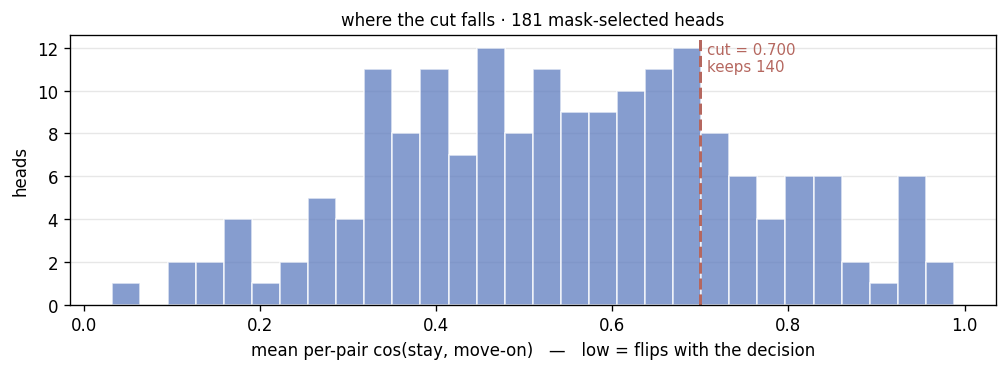

In [ ]:
# ── (CHEAP) apply the selection rule — re-run freely with different configs ──
AFF_SELECTION = "THRESHOLD"      # "THRESHOLD" | "TOP_K"
AFF_THRESHOLD = 0.7              # THRESHOLD: keep heads with mean per-pair cos BELOW this
AFF_TOP_K     = 40               # TOP_K: keep the K lowest-cosine heads
AFF_SHOW_HIST = True

if APPLY_AFFINITY_FILTER:
    assert isinstance(AFF_SEP, dict) and AFF_SEP, "run the caching cell above first"
    # Always rank the FULL mask set, never the previously-filtered one, so this cell is idempotent
    # under re-runs with a different threshold.
    _ranked = sorted(decision_heads_all, key=lambda lh: AFF_SEP[lh])
    if AFF_SELECTION == "TOP_K":
        decision_heads = _ranked[:AFF_TOP_K]
    elif AFF_SELECTION == "THRESHOLD":
        decision_heads = [lh for lh in _ranked if AFF_SEP[lh] < AFF_THRESHOLD]
    else:
        raise ValueError(f"unknown AFF_SELECTION={AFF_SELECTION!r} (want THRESHOLD | TOP_K)")
    assert decision_heads, (
        f"affinity filter kept 0 of {len(decision_heads_all)} heads — lowest cosine is "
        f"{AFF_SEP[_ranked[0]]:.3f}; raise AFF_THRESHOLD or use AFF_SELECTION='TOP_K'")
else:
    decision_heads = list(decision_heads_all)

DEC_MASK = mask_bin(decision_heads)              # every intervention below patches THIS

# Persist the head set for BOTH filter states, so a screened run is reproducible from disk and the
# two can be diffed without re-running the screen. json alongside .pt for readability.
_heads_key = dict(what="decision_heads", model=MODEL_NAME, datatype=DATATYPE, mask_tag=TAG,
                  sel_thr=SEL_THR, filter=bool(APPLY_AFFINITY_FILTER),
                  selection=(AFF_SELECTION if APPLY_AFFINITY_FILTER else None),
                  threshold=(AFF_THRESHOLD if APPLY_AFFINITY_FILTER
                             and AFF_SELECTION == "THRESHOLD" else None),
                  top_k=(AFF_TOP_K if APPLY_AFFINITY_FILTER
                         and AFF_SELECTION == "TOP_K" else None),
                  aff=(_aff_key if APPLY_AFFINITY_FILTER else None))
_ = cached("decision_heads", _heads_key, lambda: sorted(map(list, decision_heads)))
_tag = ("nofilter" if not APPLY_AFFINITY_FILTER else
        f"{AFF_SELECTION.lower()}_" + (f"{AFF_THRESHOLD:g}" if AFF_SELECTION == "THRESHOLD"
                                       else f"{AFF_TOP_K}"))
_hp = CACHE_DIR / f"decision_heads__{_tag}.json"
_hp.write_text(json.dumps(sorted(map(list, decision_heads))))
print(f"  head set -> {_hp.name}  ({len(decision_heads)} heads)")
print(f"decision heads in use: {len(decision_heads)} of {len(decision_heads_all)}"
      + (f"  ({AFF_SELECTION})" if APPLY_AFFINITY_FILTER else "  (no screen)"))

if APPLY_AFFINITY_FILTER:
    _kept = np.array([AFF_SEP[lh] for lh in decision_heads])
    _dropped = [lh for lh in decision_heads_all if lh not in set(decision_heads)]
    _drop = np.array([AFF_SEP[lh] for lh in _dropped])
    print(f"  kept    cos {_kept.min():.3f}..{_kept.max():.3f} (mean {_kept.mean():.3f})")
    if _drop.size:
        print(f"  dropped cos {_drop.min():.3f}..{_drop.max():.3f} (mean {_drop.mean():.3f})")
    _t = Table(title="most decision-separating heads (lowest cosine)", box=SIMPLE_HEAVY,
               pad_edge=False, title_justify="left")
    for _c in ("rank", "layer", "head", "per-pair cos"):
        _t.add_column(_c, justify="right")
    for _i, _lh in enumerate(_ranked[:10]):
        _t.add_row(str(_i + 1), str(_lh[0]), str(_lh[1]), f"{AFF_SEP[_lh]:.3f}")
    rich_print(_t)

    if AFF_SHOW_HIST:
        _cut = AFF_THRESHOLD if AFF_SELECTION == "THRESHOLD" else AFF_SEP[_ranked[min(
            AFF_TOP_K, len(_ranked)) - 1]]
        fig, ax = plt.subplots(figsize=(8.5, 3.2), dpi=120)
        ax.hist(list(AFF_SEP.values()), bins=30, color="#5E7CBF", alpha=0.75, edgecolor="white")
        ax.axvline(_cut, color="#B5675F", ls="--", lw=1.8)
        ax.annotate(f"cut = {_cut:.3f}\nkeeps {len(decision_heads)}", (_cut, ax.get_ylim()[1]),
                    xytext=(4, -4), textcoords="offset points", va="top", fontsize=9,
                    color="#B5675F")
        ax.set_xlabel("mean per-pair cos(stay, move-on)   —   low = flips with the decision")
        ax.set_ylabel("heads"); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
        ax.set_title(f"where the cut falls · {len(decision_heads_all)} mask-selected heads",
                     fontsize=10)
        plt.tight_layout(); plt.show()

In [ ]:
# ── §3 cases: straight-line ladders on `b`, pivot at each UNFINISHED rung ───
# ladder = ([rungs], ends_with). rung = (label, cumulative `b` lines, expected clean continuation).
# `ends_with` completes the sub-task and is recorded for reading only — it is NEVER a pivot, because
# there the clean run moves on by itself and patched has nothing to differ from.
# No multi-line `for` blocks: one statement per rung, so the next line is unambiguously either
# "still on b" or "moved on".
LEN_DESC = ([("sorted asc", ["    b = sorted(words, key=len)"], "b = b[::-1]")],
            "    b = b[::-1]")
LEN_LAMBDA = ([("key fn",     ["    b = lambda x: len(x)"], "b = sorted(words, key=b)"),
               ("sorted asc", ["    b = lambda x: len(x)", "    b = sorted(words, key=b)"],
                "b = b[::-1]")],
              "    b = b[::-1]")
LENGTHS  = ([("lengths",    ["    b = [len(w) for w in words]"], "b = sorted(b)"),
             ("sorted asc", ["    b = [len(w) for w in words]", "    b = sorted(b)"], "b = b[::-1]")],
            "    b = b[::-1]")
INITIALS = ([("letters",    ["    b = [w[0] for w in words]"], 'b = "".join(b)'),
             ("joined",     ["    b = [w[0] for w in words]", '    b = "".join(b)'], "b = b.lower()")],
            "    b = b.lower()")
LAST_LETTERS = ([("letters", ["    b = [w[-1] for w in words]"], 'b = "".join(b)'),
                 ("joined",  ["    b = [w[-1] for w in words]", '    b = "".join(b)'],
                  "b = b.upper()")],
                "    b = b.upper()")
UNIQUE   = ([("distinct",   ["    b = set(words)"], "b = sorted(b)"),
             ("sorted",     ["    b = set(words)", "    b = sorted(b)"], 'b = ", ".join(b)')],
            '    b = ", ".join(b)')
NORMED   = ([("lowercased", ["    b = [w.lower() for w in words]"], "b = set(b)"),
             ("deduped",    ["    b = [w.lower() for w in words]", "    b = set(b)"],
              "b = sorted(b)")],
            "    b = sorted(b)")
LONGEST  = ([("sorted",     ["    b = sorted(words, key=len)"], "b = b[-1]"),
             ("picked",     ["    b = sorted(words, key=len)", "    b = b[-1]"], "b = b.upper()")],
            "    b = b.upper()")
ALPHA_FIRST = ([("sorted",  ["    b = sorted(words)"], "b = b[0]"),
                ("picked",  ["    b = sorted(words)", "    b = b[0]"], "b = b.upper()")],
               "    b = b.upper()")
REVERSED_ = ([("reversed", ["    b = [w[::-1] for w in words]"], 'b = " ".join(b)'),
              ("joined",   ["    b = [w[::-1] for w in words]", '    b = " ".join(b)'],
               "b = b.lower()")],
             "    b = b.lower()")
VOWELS   = ([("counts",     ['    b = [sum(ch in "aeiou" for ch in w) for w in words]'], "b = sorted(b)"),
             ("sorted asc", ['    b = [sum(ch in "aeiou" for ch in w) for w in words]',
                             "    b = sorted(b)"], "b = b[::-1]")],
            "    b = b[::-1]")
JOINED_UPPER = ([("joined", ['    b = "-".join(words)'], "b = b.upper()")],
                "    b = b.upper()")
NO_VOWELS = ([("stripped", ['    b = ["".join(ch for ch in w if ch not in "aeiou") for w in words]'],
               'b = " ".join(b)')],
             '    b = " ".join(b)')
DEDUP_LENS = ([("lengths", ["    b = set(len(w) for w in words)"], "b = sorted(b)"),
               ("sorted",  ["    b = set(len(w) for w in words)", "    b = sorted(b)"],
                "b = b[::-1]")],
              "    b = b[::-1]")
PREFIXES = ([("prefixes", ["    b = [w[:2] for w in words]"], 'b = ", ".join(b)')],
            '    b = ", ".join(b)')
REV_ALPHA = ([("sorted",  ["    b = sorted(words)"], "b = b[::-1]")],
             "    b = b[::-1]")
CAPITALISED = ([("capitalised", ["    b = [w.capitalize() for w in words]"], 'b = " ".join(b)')],
               '    b = " ".join(b)')
LADDERS = {
    "R0_control":      LEN_DESC,      # control family: nothing downstream needs `b`
    "R0b_lengths":     LENGTHS,
    "R0c_initials":    INITIALS,
    "R0d_unique":      UNIQUE,
    "R0e_reversed":    REVERSED_,
    "R0f_longest":     LONGEST,
    "R0g_vowels":      VOWELS,
    "R1_sorted_len":   LEN_DESC,
    "R2_lengths":      LENGTHS,
    "R3_initials":     INITIALS,
    "R4_unique":       UNIQUE,
    "R5_normalized":   NORMED,
    "R6_longest":      LONGEST,
    "R7_reversed":     REVERSED_,
    "R8_vowels":       VOWELS,
    "R9_joined_upper": JOINED_UPPER,
    "R10_last_letters": LAST_LETTERS,
    "R11_no_vowels":   NO_VOWELS,
    "R12_dedup_lengths": DEDUP_LENS,
    "R13_alpha_first": ALPHA_FIRST,
    "R14_prefixes":    PREFIXES,
    "R15_reverse_alpha": REV_ALPHA,
    "R16_capitalised": CAPITALISED,
    "R17_len_lambda":  LEN_LAMBDA,
}
# every prefill = the COMPLETE two-line `a`, then the ladder's `b` lines up to this rung
CASE_FILTER = None     # e.g. "R0" -> only the no-dependency controls; None -> everything
CASES = [dict(pid=pid, depth=d, body=A_BLOCK + b, stays=s, pivot="b", ends_with=end)
         for pid, (rungs, end) in LADDERS.items() for (d, b, s) in rungs
         if CASE_FILTER is None or pid.startswith(CASE_FILTER)]
assert CASES, f"CASE_FILTER={CASE_FILTER!r} matched no prompt"
_n_ctrl = sum(1 for c in CASES if not next(p for p in PROMPTS if p["id"] == c["pid"])["dep"])
print(f"{len(CASES)} intervention candidates "
      f"({_n_ctrl} with NO dependency edge, {len(CASES) - _n_ctrl} with one) "
      f"— closing lines excluded, clean moves on there anyway")
for pid, (rungs, end) in LADDERS.items():
    if CASE_FILTER is not None and not pid.startswith(CASE_FILTER):
        continue
    print(f"  {pid:19s} {len(rungs)} rung(s): " + " -> ".join(d for d, *_ in rungs)
          + f"   [ends: {end.strip()}]")

41 intervention candidates (13 with NO dependency edge, 28 with one) — closing lines excluded, clean moves on there anyway
  R0_control          1 rung(s): sorted asc   [ends: b = b[::-1]]
  R0b_lengths         2 rung(s): lengths -> sorted asc   [ends: b = b[::-1]]
  R0c_initials        2 rung(s): letters -> joined   [ends: b = b.lower()]
  R0d_unique          2 rung(s): distinct -> sorted   [ends: b = ", ".join(b)]
  R0e_reversed        2 rung(s): reversed -> joined   [ends: b = b.lower()]
  R0f_longest         2 rung(s): sorted -> picked   [ends: b = b.upper()]
  R0g_vowels          2 rung(s): counts -> sorted asc   [ends: b = b[::-1]]
  R1_sorted_len       1 rung(s): sorted asc   [ends: b = b[::-1]]
  R2_lengths          2 rung(s): lengths -> sorted asc   [ends: b = b[::-1]]
  R3_initials         2 rung(s): letters -> joined   [ends: b = b.lower()]
  R4_unique           2 rung(s): distinct -> sorted   [ends: b = ", ".join(b)]
  R5_normalized       2 rung(s): lowercased -> deduped   

### 3a. Positive control — the intervention on `01.1`'s own prompts

Before reading anything about dependencies: does move-on work **at all** in this notebook's harness?

These are the prompts `01.1 §3` uses, built by `build_completion_pairs(datatype="list[str]")` and
run through the **same** `run_pivot`. They carry no dependency structure whatsoever, so if the
patched arm does not move on here, the problem is the setup, not the dependencies — and nothing in
§3b is interpretable.

A second block re-runs the *same* pivot on one hand-built ladder prompt, so the two differ only in
how the prompt was written (`build_example`'s `render_instruction` vs this notebook's custom
instruction), with the vector, heads, α, patch position and generation call all held fixed.

In [ ]:
# ── §3a: positive control — 01.1's prompts through the SAME run_pivot ───────
N_CTRL = 5
# one batched pass over all N_CTRL prompts, then render — same numbers as the per-prompt loop
_ctrl = CTRL_PAIRS[:N_CTRL]
_cleans, _patcheds = run_pivot([p.source.ml_prompt for p in _ctrl])   # ml = pivoted -> should STAY
n_moved = 0
for p, clean, patched in zip(_ctrl, _cleans, _patcheds):
    ctx = p.source
    ts = ctx.target_slot
    cur_v, tgt_v = chr(97 + ts), chr(97 + ts + 1)
    stay_tok = mt.tokenizer.decode([ctx.ml_ans]).strip()
    move_tok = mt.tokenizer.decode([ctx.sl_ans]).strip()
    moved = patched.strip().startswith(tgt_v)
    n_moved += moved

    rich_print(Panel(
        Group(Text.from_markup(
                  f"[bold]{escape(ctx.spec.spec_id)}[/bold] · build_completion_pairs "
                  f"({escape(DATATYPE)}) · target_slot={ts} · pivot [yellow]{cur_v}[/yellow] -> "
                  f"target [salmon1]{tgt_v}[/salmon1]  "
                  f"[grey58](stay {stay_tok!r} · move-on {move_tok!r} · "
                  f"pivot tok {pivot_token(ctx.ml_prompt)!r})[/grey58]"),
              Text(""),
              Text("\n".join(f"  {chr(97+k)}. {t}" for k, t in enumerate(ctx.spec.spec_texts)),
                   style="grey70"),
              Text(""), Text("exact prompt as the model sees it:", style="bold"),
              Text.from_markup(exact_prompt(ctx.ml_prompt))),
        border_style="grey42", padding=(1, 1)))
    t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False)
    t.add_column(f"clean — should STAY on `{cur_v}`", style="sea_green3", ratio=1, overflow="fold")
    t.add_column(f"patched — should jump to `{tgt_v}`", style="salmon1", ratio=1, overflow="fold")
    t.add_row(escape(clean.strip()), escape(patched.strip()))
    rich_print(t); rich_print("")
rich_print(f"[bold]control: patched moved on in {n_moved}/{N_CTRL}[/bold] "
           + ("[green]— harness is healthy, §3b is interpretable[/green]" if n_moved >= N_CTRL - 1
              else "[red]— the SETUP is broken; do not read §3b[/red]"))

# same pivot, this notebook's own instruction wording: isolates prompt-shape from harness
_case = CASES[0]
_p = next(x for x in PROMPTS if x["id"] == _case["pid"])
_code = STUB + "\n".join(_case["body"]) + "\n"
_user = _p["prompt"].split("<|im_start|>user")[-1].split("<|im_end|>")[0].strip()
_own = maybe_tabnewline(
    apply_chat_template(mt=mt, user_query=_user, incomplete_code=_code)) + "   "
_c2, _p2 = run_pivot(_own)
rich_print(Panel(Group(Text("exact prompt as the model sees it:", style="bold"),
                       Text.from_markup(exact_prompt(_own))),
                 title=f"[bold]{_case['pid']} / {_case['depth']}[/bold] — hand-built prompt, "
                       f"same harness (pivot tok {pivot_token(_own)!r})",
                 title_align="left", border_style="grey42", padding=(1, 1)))
t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False)
t.add_column("clean", style="sea_green3", ratio=1, overflow="fold")
t.add_column("patched", style="salmon1", ratio=1, overflow="fold")
t.add_row(escape(_c2.strip()), escape(_p2.strip()))
rich_print(t)
rich_print("[grey58]If the control block above moved on but this one does not, the difference is "
           "the PROMPT (instruction wording / ladder shape), not the intervention.[/grey58]")

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ ml_s1_mul_566423 · build_completion_pairs (list[str]) · target_slot=1 · pivot b -> target c  (stay 'b' ·        │
│ move-on 'c' · pivot tok '    \n')                                                                               │
│                                                                                                                 │
│   a. words has at least 3 entries                                                                               │
│   b. two of the words in words start with the same letter                                                       │
│   c. the words in words have more than 15 characters in total                                                   │
│   d. all words in words have the same length                                                                    │
│   e. the longest word in words has at least 3 characters                                                        │
│   f. every word in words is entirely lowercase                                                                  │
│                                                                                                                 │
│ exact prompt as the model sees it:                                                                              │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ checks the following conditions:\n                                                                              │
│ \n                                                                                                              │
│ 1. words has at least 3 entries\n                                                                               │
│ 2. two of the words in words start with the same letter\n                                                       │
│ 3. the words in words have more than 15 characters in total\n                                                   │
│ 4. all words in words have the same length\n                                                                    │
│ 5. the longest word in words has at least 3 characters\n                                                        │
│ 6. every word in words is entirely lowercase\n                                                                  │
│ \n                                                                                                              │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.\n                                    │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.\n                                                                                  │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                               

clean — should STAY on `b`                                patched — should jump to `c`                            
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b = len(b) < len(words)                                   c = sum(len(w) for w in words) > 15                     
     c = sum(len(w) for w in words)                            d = len(set(len(w) for w in words)) == 1            
     c = c > 15                                                e = max(len(w) for w in words) >= 3                 
     d = len(set(len(w) for w in words))                                                                           
     d                                                                                                            

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ ml_s1_mul_688000 · build_completion_pairs (list[str]) · target_slot=1 · pivot b -> target c  (stay 'b' ·        │
│ move-on 'c' · pivot tok '    \n')                                                                               │
│                                                                                                                 │
│   a. at least 1 words in words start with a vowel                                                               │
│   b. the words in words have more than 15 characters in total                                                   │
│   c. all words in words are distinct                                                                            │
│   d. every word in words is entirely lowercase                                                                  │
│   e. two of the words in words start with the same letter                                                       │
│                                                                                                                 │
│ exact prompt as the model sees it:                                                                              │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ checks the following conditions:\n                                                                              │
│ \n                                                                                                              │
│ 1. at least 1 words in words start with a vowel\n                                                               │
│ 2. the words in words have more than 15 characters in total\n                                                   │
│ 3. all words in words are distinct\n                                                                            │
│ 4. every word in words is entirely lowercase\n                                                                  │
│ 5. two of the words in words start with the same letter\n                                                       │
│ \n                                                                                                              │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.\n                                    │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.\n                                                                                  │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>    \n                                                                                                    │
│ def check_conditions(words: list[str]):    \n         

clean — should STAY on `b`                                patched — should jump to `c`                            
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b = b > 15                                                c = len(words) == len(set(words))                       
     c = len(words) == len(set(words))                         d = all(w.islower() for w in words)                 
     d = all(w.islower() for w in words)                       e = len(set(w[:1] for w in words)) < len(words)     
     e = len(set(w[:1] for w in words))                        print(f"                                           

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ ml_s1_mul_152727 · build_completion_pairs (list[str]) · target_slot=1 · pivot b -> target c  (stay 'b' ·        │
│ move-on 'c' · pivot tok '    \n')                                                                               │
│                                                                                                                 │
│   a. the words in words are in alphabetical order                                                               │
│   b. two of the words in words start with the same letter                                                       │
│   c. the longest word in words has at least 3 characters                                                        │
│   d. at least 1 words in words start with a vowel                                                               │
│                                                                                                                 │
│ exact prompt as the model sees it:                                                                              │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ checks the following conditions:\n                                                                              │
│ \n                                                                                                              │
│ 1. the words in words are in alphabetical order\n                                                               │
│ 2. two of the words in words start with the same letter\n                                                       │
│ 3. the longest word in words has at least 3 characters\n                                                        │
│ 4. at least 1 words in words start with a vowel\n                                                               │
│ \n                                                                                                              │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.\n                                    │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.\n                                                                                  │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>    \n                                                                                                    │
│ def check_conditions(words: list[str]):    \n                                                                   │
│     a = sorted(words)    \n                                                                                     │
│     a = a == words    \n                              

clean — should STAY on `b`                                patched — should jump to `c`                            
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b = len(b) < len(words)                                   c = max(len(w) for w in words) >= 3                     
     c = max(len(w) for w in words) >= 3                       d = any(w[0].lower() in 'aeiou' for w in words)     
     d = any(w[0].lower() in 'aeiou' for w in words)           print(f"Alphabetical order: {a},                   

... (4 outputs left out)

control: patched moved on in 5/5 — harness is healthy, §3b is interpretable

╭─ R0_control / sorted asc — hand-built prompt, same harness (pivot tok ')\n') ───────────────────────────────────╮
│                                                                                                                 │
│ exact prompt as the model sees it:                                                                              │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ computes the following:\n                                                                                       │
│ \n                                                                                                              │
│ 1. the number of words that contain the letter "e"\n                                                            │
│ 2. the words sorted by length, longest first\n                                                                  │
│ 3. whether every word is entirely lowercase\n                                                                   │
│ \n                                                                                                              │
│ For each item, in the order listed, assign the result to its own local variable, using single lowercase letters │
│ in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a     │
│ SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`\n      │
│ Compute every value inside `check_conditions` (one local variable per item); do not define any helper           │
│ functions.\n                                                                                                    │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = [w for w in words if "e" in w]\n                                                                        │
│     a = len(a)\n                                                                                                │
│     b = sorted(words, key=len)\n                                                                                │
│                                                                                                                 │
│ (PATCH_POS=-2 -> absolute token 260 of 262; highlighted above)                                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

clean                                                     patched                                                 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b.reverse()                                               c = all(w.islower() for w in words)                     
     c = all(w.islower() for w in words)                       print(f"a: {a}, b: {b}, c: {c}")                    
     print(f"a: {a}, b: {b}, c: {c}")                      </code>                                                 
 </code>                                                                                                          

If the control block above moved on but this one does not, the difference is the PROMPT (instruction wording / 
ladder shape), not the intervention.

### 3a-2. Does the sub-step have to end in a **boolean**? — 5 vs 5

The int-derived vector drives `list[str]` prompts reliably in `01.1`, so the vector's datatype is
not what separates §3a from §3b. What is left is the prompt — and the sharpest difference is what a
sub-step *is*:

* in the corpus the completion mask was trained on, every sub-step ends in a **boolean verdict**;
* in §3b every sub-step ends in a **value** — a list, a string, a number. It never reaches a verdict,
  at any rung, including the closing line.

So "this sub-step is finished" may specifically mean *a verdict has been reached*, which would make
§3b's ladders the wrong probe rather than a negative result.

**Five matched pairs.** Each pair shares a **byte-identical prefill**, so the model sees exactly the
same tokens at the pivot; the two arms differ only in what the *instruction* says the half-written
`b` is going to become, and therefore in what its one remaining line would be:

| pivot line (identical) | `boolean` arm — one line from a verdict | `value` arm — one line from a value |
|---|---|---|
| `b = set(len(w) for w in words)` | all words have the same length → `b = len(b) <= 1` | the distinct word lengths, ascending → `b = sorted(b)` |
| `b = sorted(words)` | the words are in alphabetical order → `b = b == words` | the words in reverse alphabetical order → `b = b[::-1]` |

Both arms are **exactly one line from completion**, so "how much is left" is held fixed and only the
*type of what is left* varies. The `boolean` arm uses the corpus `"checks"` instruction verbatim
(asserted against `render_instruction`); the `value` arm uses §3b's `"computes"` wording, because
telling the model to "assign the boolean result" of a condition that yields a list would be
incoherent. Wording and value-kind therefore move together — that is the contrast, not a confound to
be crossed.

In [ ]:
# ── §3a-2: does the sub-step have to end in a BOOLEAN? five matched pairs ───
# Each entry: one pivot line, and the two ways it can be finished. `cond` is how condition 2 is
# described in the instruction; `ends` is the single remaining line. Both arms are exactly ONE line
# from done, so only the TYPE of the pending result differs.
BOOL_VS_VALUE = [
    dict(id="same_length",
         pivot="    b = set(len(w) for w in words)",
         boolean=dict(cond="all words in words have the same length",     ends="b = len(b) <= 1"),
         value  =dict(cond="the distinct word lengths, in ascending order", ends="b = sorted(b)")),
    dict(id="alphabetical",
         pivot="    b = sorted(words)",
         boolean=dict(cond="the words in words are in alphabetical order", ends="b = b == words"),
         value  =dict(cond="the words in words in reverse alphabetical order", ends="b = b[::-1]")),
    dict(id="word_lengths",
         pivot="    b = [len(w) for w in words]",
         boolean=dict(cond="some word in words has at least five characters", ends="b = max(b) >= 5"),
         value  =dict(cond="the length of each word in words, in ascending order", ends="b = sorted(b)")),
    dict(id="distinct",
         pivot="    b = set(words)",
         boolean=dict(cond="all words in words are distinct",              ends="b = len(b) == len(words)"),
         value  =dict(cond="the distinct words in words, in alphabetical order", ends="b = sorted(b)")),
    dict(id="lowercased",
         pivot="    b = [w.lower() for w in words]",
         boolean=dict(cond="every word in words is entirely lowercase",    ends="b = b == words"),
         value  =dict(cond="the words in words, lowercased and in alphabetical order", ends="b = sorted(b)")),
]
# conditions 1 and 3 are FIXED across every arm — only condition 2 (the pivot's own) varies, so the
# prefill and the move-on target are held constant.
COND_A_DIAG = "the words in words are in alphabetical order"
A_BLOCK_DIAG = ["    a = sorted(words)", "    a = a == words"]
COND_C_DIAG = "words has at least three entries"

INSTR = {
 "checks": ("Write a Python program that implements a function `check_conditions` which, given a "
            "list of strings words, checks the following conditions:\n\n{body}\n\n"
            "For each condition, in the order listed, assign the boolean result of the check to its "
            "own local variable, using single lowercase letters in order — `a` for the first "
            "condition, `b` for the second, and so on. After all conditions have been checked, use a "
            "SINGLE print statement that, using those variables, reports whether each condition "
            "passed individually and whether all of them passed collectively.\n"
            "Compute each condition's boolean result inside `check_conditions` (one local variable "
            "per condition); do not define any helper functions.\n"
            "Do not include any comments in your code."),
 "computes": ("Write a Python program that implements a function `check_conditions` which, given a "
            "list of strings words, computes the following:\n\n{body}\n\n"
            "For each item, in the order listed, assign the result to its own local variable, using "
            "single lowercase letters in order — `a` for the first item, `b` for the second, and so "
            "on. After all items have been computed, use a SINGLE print statement that, using those "
            "variables, reports each result. `print(f\"a: {{a}}, b: {{b}}\", ...)`\n"
            "Compute every value inside `check_conditions` (one local variable per item); do not "
            "define any helper functions.\n"
            "Do not include any comments in your code."),
}
ARM_INSTR = {"boolean": "checks", "value": "computes"}   # wording follows the value kind

# The "checks" arm must be the corpus wording VERBATIM — it is what render_instruction emits, what
# build_example produces, and what the completion mask was trained on. Hand-copying it once already
# introduced a silent mismatch ("reports each result" vs "reports whether each condition passed"),
# which would have made this arm a hybrid rather than the in-distribution baseline.
from scripts.evaluation.eval_goalscope_old_cond_data import build_corpus as _bc
import re as _re
_ref = _bc(1, [3], 5, "list[str]")[0].render_instruction(name_rule="letters")
_ref = _re.sub(r"(?s)(conditions:\n\n).*?(\n\nFor each)", r"\g<1>{body}\g<2>", _ref)
assert INSTR["checks"].strip() == _ref.strip(), (
    "INSTR['checks'] has drifted from render_instruction:\n"
    + "\n".join(__import__("difflib").unified_diff(_ref.strip().splitlines(),
                                                    INSTR["checks"].strip().splitlines(),
                                                    lineterm="", n=0)))
print("INSTR['checks'] == render_instruction output (verbatim corpus wording)")

def diag_prompt(entry, arm):
    conds = [COND_A_DIAG, entry[arm]["cond"], COND_C_DIAG]
    body = "\n".join(f"{i+1}. {c}" for i, c in enumerate(conds))
    code = STUB + "\n".join(A_BLOCK_DIAG + [entry["pivot"]]) + "\n"
    return maybe_tabnewline(
        apply_chat_template(mt=mt, user_query=INSTR[ARM_INSTR[arm]].format(body=body),
                            incomplete_code=code)) + "   "

DIAG_ROWS = []
for entry in BOOL_VS_VALUE:
    prompts = {arm: diag_prompt(entry, arm) for arm in ("boolean", "value")}
    # the premise of the pair: identical code, identical pivot token
    _codes = {p.split("<|im_start|>assistant")[1] for p in prompts.values()}
    assert len(_codes) == 1, f"{entry['id']}: the two arms do not share a prefill"
    assert len({pivot_token(p) for p in prompts.values()}) == 1, f"{entry['id']}: pivot differs"
    for arm in ("boolean", "value"):
        pr = prompts[arm]
        clean, patched = run_pivot(pr)
        moved = patched.strip().startswith("c")
        DIAG_ROWS.append(dict(pair=entry["id"], arm=arm, cond=entry[arm]["cond"],
                              ends=entry[arm]["ends"], clean=clean, patched=patched, moved=moved))
        rich_print(Panel(
            Group(Text.from_markup(
                      f"[bold]{entry['id']}[/bold]  ·  arm [yellow]{arm}[/yellow]  "
                      f"(instruction {ARM_INSTR[arm]!r})  ·  pivot token {pivot_token(pr)!r}\n"
                      f"[grey58]2. {escape(entry[arm]['cond'])}\n"
                      f"one line from done: {escape(entry[arm]['ends'])}[/grey58]"),
                  Text(""), Text.from_markup(exact_prompt(pr))),
            border_style="grey42", padding=(1, 1)))
        t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False)
        t.add_column("clean — should STAY on `b`", style="sea_green3", ratio=1, overflow="fold")
        t.add_column("patched — should jump to `c`", style="salmon1", ratio=1, overflow="fold")
        t.add_row(escape(clean.strip()), escape(patched.strip()))
        rich_print(t); rich_print("")

t = Table(title="does the sub-step have to end in a boolean? (identical prefill within each pair)",
          box=SIMPLE_HEAVY, pad_edge=False, title_justify="left")
for c_ in ("pair", "pivot line", "boolean arm", "value arm"):
    t.add_column(c_, overflow="fold")
for entry in BOOL_VS_VALUE:
    g = {r["arm"]: r for r in DIAG_ROWS if r["pair"] == entry["id"]}
    mark = lambda r: "[green]moved on[/green]" if r["moved"] else "[red]stayed[/red]"
    t.add_row(entry["id"], escape(entry["pivot"].strip()),
              mark(g["boolean"]), mark(g["value"]))
n_b = sum(r["moved"] for r in DIAG_ROWS if r["arm"] == "boolean")
n_v = sum(r["moved"] for r in DIAG_ROWS if r["arm"] == "value")
t.add_row("[bold]TOTAL[/bold]", "", f"[bold]{n_b}/5[/bold]", f"[bold]{n_v}/5[/bold]")
rich_print(t)
rich_print("[grey58]A split between the columns means the boundary signal is about reaching a "
           "BOOLEAN VERDICT, not about finishing an arbitrary value — which would make §3b's "
           "value-producing ladders the wrong probe rather than a negative result. No split means "
           "the value kind is exonerated and the difference lies elsewhere in §3b.[/grey58]")

INSTR['checks'] == render_instruction output (verbatim corpus wording)


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ same_length  ·  arm boolean  (instruction 'checks')  ·  pivot token ')\n'                                       │
│ 2. all words in words have the same length                                                                      │
│ one line from done: b = len(b) <= 1                                                                             │
│                                                                                                                 │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ checks the following conditions:\n                                                                              │
│ \n                                                                                                              │
│ 1. the words in words are in alphabetical order\n                                                               │
│ 2. all words in words have the same length\n                                                                    │
│ 3. words has at least three entries\n                                                                           │
│ \n                                                                                                              │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.\n                                    │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.\n                                                                                  │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = sorted(words)\n                                                                                         │
│     a = a == words\n                                                                                            │
│     b = set(len(w) for w in words)\n                                                                            │
│                                                                                                                 │
│ (PATCH_POS=-2 -> absolute token 255 of 257; highlighted above)                                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

clean — should STAY on `b`                                patched — should jump to `c`                            
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b = len(b) == 1                                           c = len(words) >= 3                                     
     c = len(words) >= 3                                       print(f"Condition 1: {a}, Condition 2: {b},         
     print(f"Condition 1: {a}, Condition 2: {b},           Condition 3: {c}, All: {a and b and c}")                
 Condition 3: {c}, All: {a                                 </code>                                                

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ same_length  ·  arm value  (instruction 'computes')  ·  pivot token ')\n'                                       │
│ 2. the distinct word lengths, in ascending order                                                                │
│ one line from done: b = sorted(b)                                                                               │
│                                                                                                                 │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ computes the following:\n                                                                                       │
│ \n                                                                                                              │
│ 1. the words in words are in alphabetical order\n                                                               │
│ 2. the distinct word lengths, in ascending order\n                                                              │
│ 3. words has at least three entries\n                                                                           │
│ \n                                                                                                              │
│ For each item, in the order listed, assign the result to its own local variable, using single lowercase letters │
│ in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a     │
│ SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`\n      │
│ Compute every value inside `check_conditions` (one local variable per item); do not define any helper           │
│ functions.\n                                                                                                    │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = sorted(words)\n                                                                                         │
│     a = a == words\n                                                                                            │
│     b = set(len(w) for w in words)\n                                                                            │
│                                                                                                                 │
│ (PATCH_POS=-2 -> absolute token 252 of 254; highlighted above)                                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

clean — should STAY on `b`                                patched — should jump to `c`                            
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b = sorted(b)                                             c = len(words) >= 3                                     
     c = len(words) >= 3                                       print(f"a: {a}, b: {b}, c: {c}")                    
     print(f"a: {a}, b: {b}, c: {c}")                      </code>                                                 
 </code>                                                                                                          

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ alphabetical  ·  arm boolean  (instruction 'checks')  ·  pivot token ')\n'                                      │
│ 2. the words in words are in alphabetical order                                                                 │
│ one line from done: b = b == words                                                                              │
│                                                                                                                 │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ checks the following conditions:\n                                                                              │
│ \n                                                                                                              │
│ 1. the words in words are in alphabetical order\n                                                               │
│ 2. the words in words are in alphabetical order\n                                                               │
│ 3. words has at least three entries\n                                                                           │
│ \n                                                                                                              │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.\n                                    │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.\n                                                                                  │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = sorted(words)\n                                                                                         │
│     a = a == words\n                                                                                            │
│     b = sorted(words)\n                                                                                         │
│                                                                                                                 │
│ (PATCH_POS=-2 -> absolute token 249 of 251; highlighted above)                                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

... (13 outputs left out)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ lowercased  ·  arm value  (instruction 'computes')  ·  pivot token ']\n'                                        │
│ 2. the words in words, lowercased and in alphabetical order                                                     │
│ one line from done: b = sorted(b)                                                                               │
│                                                                                                                 │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ computes the following:\n                                                                                       │
│ \n                                                                                                              │
│ 1. the words in words are in alphabetical order\n                                                               │
│ 2. the words in words, lowercased and in alphabetical order\n                                                   │
│ 3. words has at least three entries\n                                                                           │
│ \n                                                                                                              │
│ For each item, in the order listed, assign the result to its own local variable, using single lowercase letters │
│ in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a     │
│ SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`\n      │
│ Compute every value inside `check_conditions` (one local variable per item); do not define any helper           │
│ functions.\n                                                                                                    │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = sorted(words)\n                                                                                         │
│     a = a == words\n                                                                                            │
│     b = [w.lower() for w in words]\n                                                                            │
│                                                                                                                 │
│ (PATCH_POS=-2 -> absolute token 255 of 257; highlighted above)                                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

clean — should STAY on `b`                                patched — should jump to `c`                            
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b = sorted(b) == b                                        c = len(words) >= 3                                     
     c = len(words) >= 3                                       print(f"a: {a}, b: {b}, c: {c}")                    
     print(f"a: {a}, b: {b}, c: {c}")                      </code>                                                 
 </code>                                                                                                          

does the sub-step have to end in a boolean? (identical prefill within    
each pair)                                                               
                                                                         
 pair           pivot line                       boolean arm   value arm 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 same_length    b = set(len(w) for w in words)   moved on      moved on  
 alphabetical   b = sorted(words)                moved on      moved on  
 word_lengths   b = [len(w) for w in words]      moved on      moved on  
 distinct       b = set(words)                   moved on      moved on  
 lowercased     b = [w.lower() for w in words]   moved on      moved on  
 TOTAL                                           5/5           5/5

A split between the columns means the boundary signal is about reaching a BOOLEAN VERDICT, not about finishing an 
arbitrary value — which would make §3b's value-producing ladders the wrong probe rather than a negative result. No 
split means the value kind is exonerated and the difference lies elsewhere in §3b.

In [ ]:
# ── §3 run: clean vs move-on-patched at every rung ──────────────────────────
def build_case_prompt(case):
    """The pivoted prompt for one ladder rung — split out so a whole batch can be built first."""
    p = next(x for x in PROMPTS if x["id"] == case["pid"])
    code = STUB + "\n".join(case["body"]) + "\n"
    user = p["prompt"].split("<|im_start|>user")[-1].split("<|im_end|>")[0].strip()
    full = apply_chat_template(mt=mt, user_query=user, incomplete_code=code)
    return maybe_tabnewline(full) + "   ", p, code


def show_case(case, clean=None, patched=None, max_new=MAX_NEW):
    prompt, p, code = build_case_prompt(case)
    pivot_tok = pivot_token(prompt)
    if clean is None:                                 # single-case fallback
        clean, patched = run_pivot(prompt, max_new)
    dep_s = ", ".join(f"{c}<-{pr}" for c, pr in p["dep"]) or "—"
    # Every case is an UNFINISHED rung, so the clean run should stay on `b`. `ends_with` is the
    # line that would close the sub-task, shown so the remaining distance is visible.
    kind = (f"[grey58]clean should STAY on `b`, i.e. write: {case['stays']}"
            f"   \u00b7   sub-task closes at: {case['ends_with'].strip()}[/grey58]")
    rich_print(Panel(
        Group(Text.from_markup(
                  f"[bold]{case['pid']}[/bold]  ·  rung [yellow]{case['depth']}[/yellow]"
                  f"  ·  edges {dep_s}  ·  pivot token {pivot_tok!r}\n{p['note']}\n{kind}"),
              Text(""),
              Text("\n".join(f"{i+1}. {c}" for i, c in enumerate(p["all_conds"])), style="grey70"),
              Text(""),
              Text("exact prompt as the model sees it:", style="bold"),
              Text.from_markup(exact_prompt(prompt))),
        border_style="grey42", padding=(1, 1)))
    t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False)
    t.add_column("clean  (no patch)", style="sea_green3", ratio=1, overflow="fold")
    t.add_column("patched  (move-on injected)", style="salmon1", ratio=1, overflow="fold")
    t.add_row(escape(clean.strip()), escape(patched.strip()))
    rich_print(t); rich_print("")
    return dict(pid=case["pid"], rung=case["depth"],
                clean=clean.strip(), patched=patched.strip())

# build every prompt first, run them in batches of BATCH_SIZE, then render in order
_prompts = [build_case_prompt(c)[0] for c in CASES]
_cleans, _patcheds = run_pivot(
    _prompts, 
    batch_size=1
)
RESULTS = [show_case(c, cl, pa) for c, cl, pa in zip(CASES, _cleans, _patcheds)]
print(f"{len(RESULTS)} generations — see RESULTS for the raw text")

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0_control  ·  rung sorted asc  ·  edges —  ·  pivot token ')\n'                                                │
│ TRANSFER CHECK: same ladder on `b`, but nothing downstream depends on it                                        │
│ clean should STAY on `b`, i.e. write: b = b[::-1]   ·   sub-task closes at: b = b[::-1]                         │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the words sorted by length, longest first                                                                    │
│ 3. whether every word is entirely lowercase                                                                     │
│                                                                                                                 │
│ exact prompt as the model sees it:                                                                              │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ computes the following:\n                                                                                       │
│ \n                                                                                                              │
│ 1. the number of words that contain the letter "e"\n                                                            │
│ 2. the words sorted by length, longest first\n                                                                  │
│ 3. whether every word is entirely lowercase\n                                                                   │
│ \n                                                                                                              │
│ For each item, in the order listed, assign the result to its own local variable, using single lowercase letters │
│ in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a     │
│ SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`\n      │
│ Compute every value inside `check_conditions` (one local variable per item); do not define any helper           │
│ functions.\n                                                                                                    │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = [w for w in words if "e" in w]\n                                                                        │
│     a = len(a)\n                                                                                                │
│     b = sorted(words, key=len)\n                                                                                │
│                                                       

clean  (no patch)                                         patched  (move-on injected)                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b.reverse()                                               c = all(w.islower() for w in words)                     
     c = all(w.islower() for w in words)                       print(f"a: {a}, b: {b}, c: {c}")                    
     print(f"a: {a}, b: {b}, c: {c}")                      </code>                                                 
 </code>                                                                                                          

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0b_lengths  ·  rung lengths  ·  edges —  ·  pivot token ']\n'                                                  │
│ CONTROL: numeric ladder, free consumer                                                                          │
│ clean should STAY on `b`, i.e. write: b = sorted(b)   ·   sub-task closes at: b = b[::-1]                       │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the lengths of the words, largest first                                                                      │
│ 3. whether any word contains a digit                                                                            │
│                                                                                                                 │
│ exact prompt as the model sees it:                                                                              │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ computes the following:\n                                                                                       │
│ \n                                                                                                              │
│ 1. the number of words that contain the letter "e"\n                                                            │
│ 2. the lengths of the words, largest first\n                                                                    │
│ 3. whether any word contains a digit\n                                                                          │
│ \n                                                                                                              │
│ For each item, in the order listed, assign the result to its own local variable, using single lowercase letters │
│ in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a     │
│ SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`\n      │
│ Compute every value inside `check_conditions` (one local variable per item); do not define any helper           │
│ functions.\n                                                                                                    │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = [w for w in words if "e" in w]\n                                                                        │
│     a = len(a)\n                                                                                                │
│     b = [len(w) for w in words]\n                                                                               │
│                                                       

clean  (no patch)                                         patched  (move-on injected)                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b.sort(reverse=True)                                      c = any(any(char.isdigit() for char in w) for w in      
     c = any(any(char.isdigit() for char in w) for w in    words)                                                  
 words)                                                        print(f"a: {a}, b: {b}, c: {c}")                    
     print(f"a: {a}, b: {b}, c: {c}")                      </code>                                                 
 </code>                                                                                                          

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R0b_lengths  ·  rung sorted asc  ·  edges —  ·  pivot token ')\n'                                               │
│ CONTROL: numeric ladder, free consumer                                                                          │
│ clean should STAY on `b`, i.e. write: b = b[::-1]   ·   sub-task closes at: b = b[::-1]                         │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the lengths of the words, largest first                                                                      │
│ 3. whether any word contains a digit                                                                            │
│                                                                                                                 │
│ exact prompt as the model sees it:                                                                              │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ computes the following:\n                                                                                       │
│ \n                                                                                                              │
│ 1. the number of words that contain the letter "e"\n                                                            │
│ 2. the lengths of the words, largest first\n                                                                    │
│ 3. whether any word contains a digit\n                                                                          │
│ \n                                                                                                              │
│ For each item, in the order listed, assign the result to its own local variable, using single lowercase letters │
│ in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a     │
│ SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`\n      │
│ Compute every value inside `check_conditions` (one local variable per item); do not define any helper           │
│ functions.\n                                                                                                    │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = [w for w in words if "e" in w]\n                                                                        │
│     a = len(a)\n                                                                                                │
│     b = [len(w) for w in words]\n                                                                               │
│     b = sorted(b)\n                                   

clean  (no patch)                                         patched  (move-on injected)                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b.reverse()                                               c = any(any(char.isdigit() for char in w) for w in      
     c = any(any(char.isdigit() for char in w) for w in    words)                                                  
 words)                                                        print(f"a: {a}, b: {b}, c: {c}")                    
     print(f"a: {a}, b: {b}, c: {c}")                      </code>                                                 
 </code>                                                                                                          

... (73 outputs left out)

clean  (no patch)                                         patched  (move-on injected)                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b = sorted(words, key=b, reverse=True)                    c = sorted(words, key=len, reverse=True)                
     c = len(b[0]) > 5                                         d = len(c[0]) > 5                                   
     print(f"a: {a}, b: {b}, c: {c}")                          print(f"a: {a}, b: {c}, d: {d}")                    
 </code>                                                   </code>                                                

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ R17_len_lambda  ·  rung sorted asc  ·  edges c<-b  ·  pivot token ')\n'                                         │
│ the key function is itself a rung — b is bound to a lambda before it is a list                                  │
│ clean should STAY on `b`, i.e. write: b = b[::-1]   ·   sub-task closes at: b = b[::-1]                         │
│                                                                                                                 │
│ 1. the number of words that contain the letter "e"                                                              │
│ 2. the words sorted by length, longest first                                                                    │
│ 3. whether the longest word is longer than five characters                                                      │
│                                                                                                                 │
│ exact prompt as the model sees it:                                                                              │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ computes the following:\n                                                                                       │
│ \n                                                                                                              │
│ 1. the number of words that contain the letter "e"\n                                                            │
│ 2. the words sorted by length, longest first\n                                                                  │
│ 3. whether the longest word is longer than five characters\n                                                    │
│ \n                                                                                                              │
│ For each item, in the order listed, assign the result to its own local variable, using single lowercase letters │
│ in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a     │
│ SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`\n      │
│ Compute every value inside `check_conditions` (one local variable per item); do not define any helper           │
│ functions.\n                                                                                                    │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = [w for w in words if "e" in w]\n                                                                        │
│     a = len(a)\n                                                                                                │
│     b = lambda x: len(x)\n                                                                                      │
│     b = sorted(words, key=b)\n                        

clean  (no patch)                                         patched  (move-on injected)                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 b.reverse()                                               c = max(words, key=len)                                 
     c = len(b[0]) > 5                                         c = len(c) > 5                                      
     print(f"a: {a}, b: {b}, c: {c}")                          print(f"a: {a}, b: {b}, c: {c}")                    
 </code>                                                   </code>                                                

41 generations — see RESULTS for the raw text


## 4. Additive steering — the same signal injected instead of transplanted

Everything above uses `replace`: the selected heads' o_proj inputs are *substituted*, which DELETES
the destination's own write. This section builds the aggregated vectors and injects them ADDITIVELY,
which leaves that write intact. Kept at the end because it depends on the screened `decision_heads`
from §3-pre and on `MEAN_SRC` / `MEAN_STAY`, and because it is exploratory rather than part of the
dependency result.

* `MOVE_ON_STEER` — raw aggregate in boundary contexts. What `replace` transplants.
* `STAY_STEER` — the same in mid-sub-step contexts. Doubles as the control: inject it at the same
  α and if the program advances anyway, the effect was the component shared with move-on.
* `MOVE_ON_SHIFT_STEER` — their difference: what actually changes when the sub-step finishes, and
  the closest additive analogue to what `replace` achieves by deletion.
* `*_BY_LAYER` — each layer's own write, so the injection can mirror `replace`'s depth structure
  instead of collapsing 43 layers of heads into one vector.

In [ ]:
# ── the steering vectors — built from the FINAL (screened) decision_heads ────
# ── the two additive vectors ────────────────────────────────────────────────
# MOVE_ON_STEER       raw aggregate of the decision heads in boundary contexts. This is what the
#                     REPLACE arm transplants, so it is the right object there — the mask picks the
#                     heads and the source value goes in wholesale.
# STAY_STEER          the same aggregate in mid-sub-step contexts.
# MOVE_ON_SHIFT_STEER their difference: what changes when the sub-step finishes. For an ADDITIVE
#                     injection this is usually the one you want — the raw mean also carries
#                     everything common to both contexts (position, indentation, "inside a code
#                     block"), so `h + alpha*MOVE_ON_STEER` adds a large shared component alongside
#                     the decision-relevant part. `16 §1` draws the same raw-vs-contrast
#                     distinction. STAY_STEER doubles as the control: inject it at the same alpha,
#                     and if the program advances anyway, the effect was the shared component.
# Cheap given the means (a few matmuls), but cached anyway so a restart reproduces the exact
# vectors rather than recomputing from possibly-changed heads.
_steer_key = dict(_means_key, what="steer", heads=sorted(map(list, decision_heads)))
MOVE_ON_STEER, STAY_STEER = cached(
    "steer", _steer_key,
    lambda: (steering_vec_from_o_proj(MEAN_SRC,  decision_heads, dec_layers),
             steering_vec_from_o_proj(MEAN_STAY, decision_heads, dec_layers)))
MOVE_ON_SHIFT_STEER = MOVE_ON_STEER - STAY_STEER

_cos = torch.nn.functional.cosine_similarity(MOVE_ON_STEER, STAY_STEER, dim=0).item()
print(f"MOVE_ON_STEER       ||v||={MOVE_ON_STEER.norm():.3f}")
print(f"STAY_STEER          ||v||={STAY_STEER.norm():.3f}")
print(f"MOVE_ON_SHIFT_STEER ||v||={MOVE_ON_SHIFT_STEER.norm():.3f}   "
      f"({MOVE_ON_SHIFT_STEER.norm() / MOVE_ON_STEER.norm():.1%} of the raw vector)")
print(f"  cos(move_on, stay) = {_cos:.4f}  — near 1 means the two contexts share most of the "
      f"aggregate and the CONTRAST is what carries the decision")

# sanity: dropping every head must give exactly zero, and the per-head parts must sum to the whole
_zero = steering_vec_from_o_proj(MEAN_SRC, [], dec_layers)
_v, _parts = steering_vec_from_o_proj(MEAN_SRC, decision_heads, dec_layers, per_head=True)
print(f"  empty head set -> ||v||={_zero.norm():.3g} (must be 0) · per-head parts sum to the "
      f"total: {torch.allclose(torch.stack(list(_parts.values())).sum(0), _v, atol=1e-4)}")


# Per-layer versions of the two vectors — same heads, same means, depth preserved.
MOVE_ON_STEER_BY_LAYER, MOVE_ON_SHIFT_STEER_BY_LAYER = cached(
    "steer_by_layer", dict(_steer_key, what="steer_by_layer"),
    lambda: (steer_by_layer(MEAN_SRC), steer_by_layer(MEAN_SRC, MEAN_STAY)))
_nz = [l for l, v in MOVE_ON_SHIFT_STEER_BY_LAYER.items() if v.norm() > 0]
_sum = torch.stack(list(MOVE_ON_SHIFT_STEER_BY_LAYER.values())).sum(0)
print(f"per-layer shift vectors: {len(_nz)} layers carry heads (span {min(_nz)}..{max(_nz)}) · "
      f"sum matches the collapsed vector: "
      f"{torch.allclose(_sum, MOVE_ON_SHIFT_STEER, atol=1e-3)}")
_band = list(range(40, 50))
_in = torch.stack([MOVE_ON_SHIFT_STEER_BY_LAYER[l] for l in _band]).sum(0).norm()
print(f"  ||shift|| from layers {_band[0]}-{_band[-1]} alone = {_in:.2f} of "
      f"{MOVE_ON_SHIFT_STEER.norm():.2f} total — injecting the COLLAPSED vector at that band "
      f"misplaces the rest")

  [cache hit ] steer  (steer__89d8d35d94.pt)
MOVE_ON_STEER       ||v||=158.977
STAY_STEER          ||v||=162.680
MOVE_ON_SHIFT_STEER ||v||=169.755   (106.8% of the raw vector)
  cos(move_on, stay) = 0.4431  — near 1 means the two contexts share most of the aggregate and the CONTRAST is what carries the decision
  empty head set -> ||v||=0 (must be 0) · per-head parts sum to the total: True
  [cache hit ] steer_by_layer  (steer_by_layer__ea852df0ba.pt)
per-layer shift vectors: 41 layers carry heads (span 11..62) · sum matches the collapsed vector: True
  ||shift|| from layers 40-49 alone = 93.08 of 169.76 total — injecting the COLLAPSED vector at that band misplaces the rest


### 4a. Why does `replace` move on but `additive` not?

Three asymmetries, separated below rather than guessed at.

1. **`replace` DELETES the stay signal.** Its hook is
   `new = alpha*m*src + (1-m)*cascade`, so at `m=1` the destination's own head output is *zeroed
   and substituted*. Those heads were writing "stay, the sub-step isn't finished"; replace removes
   that. Additive leaves it fully intact and adds on top, so it is competing with an undamaged
   opposing signal — something no `alpha` fixes by addition alone.
2. **`MOVE_ON_STEER` is the raw aggregate**, dominated by whatever is shared with `STAY_STEER`.
   `MOVE_ON_SHIFT_STEER` is the additive analogue of what replace does by deletion.
3. **Different injection sites.** `replace` patches the o_proj *input* — inside attention, BEFORE
   that layer's MLP. Additive patches the decoder-layer *output* — the residual after attention AND
   MLP. Same layer index, strictly later in the block.

The sweep varies only the vector and `alpha`, holding the layers, position and generation call
fixed, with `replace` as the reference row.

In [ ]:
# ── §4a: which vector, and at what alpha, reproduces `replace`? ─────────────
from src.goals.goalscope import head_additive_generate

DIAG_CASE   = CASES[0]                      # any pivoted prompt; CASES[0] by default
ADD_LAYERS  = list(range(40, 50))           # where the decision heads concentrate
ALPHAS      = [0.1, 0.3, 1.0, 3.0, 10.0]
ADD_STRATEGY = "additive_norm"              # alpha = fraction of the local ||h||

_p = next(x for x in PROMPTS if x["id"] == DIAG_CASE["pid"])
_code = STUB + "\n".join(DIAG_CASE["body"]) + "\n"
_user = _p["prompt"].split("<|im_start|>user")[-1].split("<|im_end|>")[0].strip()
_pr = maybe_tabnewline(
    apply_chat_template(mt=mt, user_query=_user, incomplete_code=_code)) + "   "
_inp = prepare_input(prompts=_pr, tokenizer=mt)
_tgt = chr(ord(DIAG_CASE["pivot"]) + 1)     # the letter a successful move-on should emit

def _moved(txt):
    return txt.strip().startswith(_tgt)

# reference rows: the replace arm that works, and its unpatched control
_clean, _repl = run_pivot(_pr)
rich_print(f"[bold]reference[/bold]  clean -> {'MOVED' if _moved(_clean) else 'stayed'} | "
           f"replace -> {'MOVED' if _moved(_repl) else 'stayed'}   "
           f"[grey58](target letter {_tgt!r})[/grey58]")
rich_print(f"[grey58]clean  : {escape(_clean.strip()[:88])}[/grey58]")
rich_print(f"[grey58]replace: {escape(_repl.strip()[:88])}[/grey58]\n")

VECS = {"MOVE_ON_STEER": MOVE_ON_STEER,            # raw aggregate — mostly shared with stay
        "MOVE_ON_SHIFT_STEER": MOVE_ON_SHIFT_STEER,  # the contrast: what replace effectively does
        "STAY_STEER": STAY_STEER}                    # control: should NOT move on
t = Table(title=f"additive sweep · {ADD_STRATEGY} · layers {ADD_LAYERS[0]}-{ADD_LAYERS[-1]} · "
                f"pos {PATCH_POS} · target {_tgt!r}", box=SIMPLE_HEAVY, pad_edge=False,
          title_justify="left")
t.add_column("vector"); t.add_column("||v||", justify="right")
for a in ALPHAS:
    t.add_column(f"a={a:g}", justify="center")
DIAG_OUT = {}
for name, vec in VECS.items():
    cells = []
    for a in ALPHAS:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")      # PATCH_POS=-2 -> prefill-only, expected here
            g = head_additive_generate(mt, dict(_inp), vec, ADD_LAYERS,
                                       max_new_tokens=MAX_NEW, strategy=ADD_STRATEGY,
                                       n_steer_tokens=1, patch_input_positions=[PATCH_POS],
                                       alpha=a)
        DIAG_OUT[(name, a)] = g
        cells.append("[green]MOVED[/green]" if _moved(g) else
                     ("[grey42]—[/grey42]" if g.strip() else "[red]empty[/red]"))
    t.add_row(name, f"{vec.norm():.2f}", *cells)
rich_print(t)
rich_print("[grey58]Read DOWN the columns: if SHIFT moves on where MOVE_ON does not, the raw "
           "vector was mostly the component shared with stay (asymmetry 2). If STAY also moves on, "
           "the effect is not the decision at all. If every cell is empty/garbage at high alpha, "
           "the injection has destroyed the representation rather than steered it — with "
           "additive_norm, alpha is a FRACTION of ||h||, so alpha=10 adds 10x the residual norm at "
           "each of the layers.[/grey58]")

for (name, a), g in DIAG_OUT.items():
    if _moved(g):
        rich_print(f"\n[bold]{name} @ alpha={a:g}[/bold]  {escape(g.strip()[:110])}")

reference  clean -> stayed | replace -> MOVED   (target letter 'c')

clean  : b.reverse()
    c = all(w.islower() for w in words)
    print(f"a: {a}, b: {b}, c: {c}")

replace: c = all(w.islower() for w in words)
    print(f"a: {a}, b: {b}, c: {c}")
</code>

additive sweep · additive_norm · layers 40-49 · pos -2 · target  
'c'                                                              
                                                                 
 vector                 ||v||   a=0.1   a=0.3   a=1   a=3   a=10 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 MOVE_ON_STEER         158.98     —       —      —     —     —   
 MOVE_ON_SHIFT_STEER   169.76   MOVED     —      —     —     —   
 STAY_STEER            162.68     —       —      —     —     —

Read DOWN the columns: if SHIFT moves on where MOVE_ON does not, the raw vector was mostly the component shared 
with stay (asymmetry 2). If STAY also moves on, the effect is not the decision at all. If every cell is 
empty/garbage at high alpha, the injection has destroyed the representation rather than steered it — with 
additive_norm, alpha is a FRACTION of ||h||, so alpha=10 adds 10x the residual norm at each of the layers.

MOVE_ON_SHIFT_STEER @ alpha=0.1  c = all(w.islower() for w in words)
    print(f"a: {a}, b: {b}, c: {c}")
</code>

## Scratch

Ad-hoc cells; nothing above depends on them.

In [ ]:
case = CASES[0]
p = next(x for x in PROMPTS if x["id"] == case["pid"])
code = STUB + "\n".join(case["body"]) + "\n"
user = p["prompt"].split("<|im_start|>user")[-1].split("<|im_end|>")[0].strip()
full = apply_chat_template(mt=mt, user_query=user, incomplete_code=code)
prompt = maybe_tabnewline(full) + "   "

rich_print(escape(prompt))

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given a list of strings words, computes
the following:

1. the number of words that contain the letter "e"
2. the words sorted by length, longest first
3. whether every word is entirely lowercase

For each item, in the order listed, assign the result to its own local variable, using single lowercase letters in 
order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a SINGLE 
print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`
Compute every value inside `check_conditions` (one local variable per item); do not define any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(words: list[str]):
    a = [w for w in words if "e" in w]
    a = len(a)
    b = sorted(words, key=len)

In [ ]:
MEAN_SRC.shape, MOVE_ON_STEER.shape, MOVE_ON_SHIFT_STEER.shape, STAY_STEER.shape

(torch.Size([64, 5120]),
 torch.Size([5120]),
 torch.Size([5120]),
 torch.Size([5120]))

In [ ]:
# prompt = """<|im_start|>system
# You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
# <|im_start|>user
# Write a Python program that implements a function `check_conditions` which, given a list of strings words, checks the following conditions:

# 1. words has at least 3 entries
# 2. two of the words in words start with the same letter
# 3. the words in words have more than 15 characters in total
# 4. all words in words have the same length
# 5. the longest word in words has at least 3 characters
# 6. every word in words is entirely lowercase

# For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports each result.
# Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define any helper functions.
# Do not include any comments in your code.<|im_end|>
# <|im_start|>assistant
# <code>    
# def check_conditions(words: list[str]):    
#     a = len(words)    
#     a = a >= 3    
#     b = set(w[:1].lower() for w in words)    
#     """

In [ ]:
entry = [cse for cse in BOOL_VS_VALUE if cse["id"] == "word_lengths"][0]
rich_print(entry)
prompts_per_arm = {arm: diag_prompt(entry, arm) for arm in ("boolean", "value")}
prompt = prompts_per_arm["value"]
print(prompt)

{
    'id': 'word_lengths',
    'pivot': '    b = [len(w) for w in words]',
    'boolean': {'cond': 'some word in words has at least five characters', 'ends': 'b = max(b) >= 5'},
    'value': {'cond': 'the length of each word in words, in ascending order', 'ends': 'b = sorted(b)'}
}

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given a list of strings words, computes the following:

1. the words in words are in alphabetical order
2. the length of each word in words, in ascending order
3. words has at least three entries

For each item, in the order listed, assign the result to its own local variable, using single lowercase letters in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`
Compute every value inside `check_conditions` (one local variable per item); do not define any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_sta

In [ ]:
prompt = [build_case_prompt(c)[0] for c in CASES if c["pid"] == "R10_last_letters"][0]
prompt = maybe_tabnewline(prompt)
print(prompt)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given a list of strings words, computes the following:

1. the number of words that contain the letter "e"
2. the last letters of the words, joined into one string, in upper case
3. whether the last letters of the words, taken in order, include a vowel

For each item, in the order listed, assign the result to its own local variable, using single lowercase letters in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`
Compute every value inside `check_conditions` (one local variable per item); do not define any helper functions.
Do 

In [ ]:
# ── alpha sweep on one prompt: exact prompt + a generation per strength ─────
SWEEP_PROMPT  = prompt           # the pivoted prompt to steer
SWEEP_MASK    = DEC_MASK         # e.g. DEC_MASK.restrict_to_layers(lo, hi) to band it
SWEEP_ALPHAS  = [2.0, 4.0, 6.0, 8.0, 12.0, 16.0]
SWEEP_VEC     = MEAN_SRC         # transplant source (replace strategy)
SWEEP_MAXNEW  = 128

def show_alpha_sweep(prompt, mask, alphas, vec=MEAN_SRC, layers=None, max_new=SWEEP_MAXNEW):
    """Prompt panel (pivot marked) + a tall table: clean row, then one row per alpha."""
    layers = dec_layers if layers is None else layers
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    hdr = (f"pivot [yellow]{pivot_token(prompt)!r}[/yellow] at PATCH_POS={PATCH_POS}   ·   "
           f"[salmon1]{mask.n_active()}[/salmon1] heads @ layers {min(layers)}-{max(layers)}   ·   "
           f"replace, n_steer_tokens=1")
    rich_print(Panel(Group(Text.from_markup(hdr), Text(""),
                           Text("exact prompt as the model sees it:", style="bold"),
                           Text.from_markup(exact_prompt(prompt))),
                     title="[bold]prompt[/bold]", title_align="left",
                     border_style="grey42", padding=(1, 1)))

    clean = headpatched_generate(mt, dict(inp), vec, NULL_MASK, layers,
                                 max_new_tokens=max_new, patch_input_positions=[PATCH_POS])
    t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False, show_lines=True,
              title=f"replace sweep · {mask.n_active()} heads @ layers {min(layers)}-{max(layers)}",
              title_justify="left")
    t.add_column("α", justify="right", no_wrap=True)
    t.add_column("generation", ratio=1, overflow="fold")
    t.add_row("[sea_green3]clean[/sea_green3]", f"[sea_green3]   {escape(clean.rstrip())}[/sea_green3]")
    for a in alphas:
        gen = headpatched_generate(mt, dict(inp), vec, mask, layers, max_new_tokens=max_new,
                                   n_steer_tokens=1, patch_input_positions=[PATCH_POS], alpha=a)
        t.add_row(f"[bold salmon1]{float(a)}[/bold salmon1]",
                  f"[salmon1]   {escape(gen.rstrip())}[/salmon1]")
    rich_print(t)

show_alpha_sweep(SWEEP_PROMPT, SWEEP_MASK, SWEEP_ALPHAS, vec=SWEEP_VEC)

╭─ prompt ────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ pivot ']\n' at PATCH_POS=-2   ·   140 heads @ layers 0-63   ·   replace, n_steer_tokens=1                       │
│                                                                                                                 │
│ exact prompt as the model sees it:                                                                              │
│ <|im_start|>system\n                                                                                            │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>\n                            │
│ <|im_start|>user\n                                                                                              │
│ Write a Python program that implements a function `check_conditions` which, given a list of strings words,      │
│ computes the following:\n                                                                                       │
│ \n                                                                                                              │
│ 1. the number of words that contain the letter "e"\n                                                            │
│ 2. the last letters of the words, joined into one string, in upper case\n                                       │
│ 3. whether the last letters of the words, taken in order, include a vowel\n                                     │
│ \n                                                                                                              │
│ For each item, in the order listed, assign the result to its own local variable, using single lowercase letters │
│ in order — `a` for the first item, `b` for the second, and so on. After all items have been computed, use a     │
│ SINGLE print statement that, using those variables, reports each result. `print(f"a: {a}, b: {b}", ...)`\n      │
│ Compute every value inside `check_conditions` (one local variable per item); do not define any helper           │
│ functions.\n                                                                                                    │
│ Do not include any comments in your code.<|im_end|>\n                                                           │
│ <|im_start|>assistant\n                                                                                         │
│ <code>\n                                                                                                        │
│ def check_conditions(words: list[str]):\n                                                                       │
│     a = [w for w in words if "e" in w]\n                                                                        │
│     a = len(a)\n                                                                                                │
│     b = [w[-1] for w in words]\n                                                                                │
│                                                                                                                 │
│ (PATCH_POS=-2 -> absolute token 280 of 282; highlighted above)                                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

replace sweep · 140 heads @ layers 0-63                                                                            
                                                                                                                   
     α   generation                                                                                                
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 clean       b = "".join(b).upper()                                                                                
             c = any(v in "AEIOU" for v in b)                                                                      
             print(f"a: {a}, b: {b}, c: {c}")                                                                      
         </code>                                                                                                   
                                                                                                                   
   2.0       b = "".join(b).upper()                                                                                
             c = any(l in "AEIOU" for l in b)                                                                      
             print(f"a: {a}, b: {b}, c: {c}")                                                                      
         </code>                                                                                                   
                                                                                                                   
   4.0       c = [w[-1] for w in words]                                                                            
             c = any(v in "aeiou" for v in c)                                                                      
             print(f"a: {a}, b: {''.join(c.upper() for c in b)}, c: {c}")                                          
         </code>                                                                                                   
                                                                                                                   
         Note: There was a mistake in the print statement of the original response. Here is the corrected version: 
                                                                                                                   
         <code>                                                                                                    
         def check_conditions(words: list[str]):                                                                   
             a = sum("e" in w for w in words)                                                                      
             b = ''.join(w[-1].upper() for w in words)                                                             
             c = any(w[-1].lower()                                                                                 
                                                                                                                   
   6.0       c = any(w[-1].lower() in "aeiou" for w in words)                                                      
             b = "".join(b).upper()                                                                                
             print(f"a: {a}, b: {b}, c: {c}")                                                                      
         </code>                                                                                                   
                                                                                                                   
   8.0       c = any(w[-1].lower() in "aeiou" for w in words)                                                      
             b = "".join(b).upper()                                                                                
             print(f"a: {a}, b: {b}, c: {c}")           

In [ ]:
inp = prepare_input(prompts=prompt, tokenizer=mt)
replace = headpatched_generate(
    mt,
    dict(inp),
    MEAN_SRC,
    DEC_MASK.restrict_to_layers(lo=5, hi=50),
    max_new_tokens=64,
    n_steer_tokens=1,
    patch_input_positions=[PATCH_POS],
    alpha=4.0,
)
rich_print(f"[bright_yellow]   {escape(replace)}[/bright_yellow]")

    c = [w[-1] for w in words]
    c = any(v in "aeiou" for v in c)
    print(f"a: {a}, b: {''.join(c.upper() for c in [w[-1] for w in words])}, c: {c}")
</code

In [ ]:
DEC_MASK.restrict_to_layers(lo=30, hi=50).n_active()

100

In [ ]:
from src.goals.goalscope import head_additive_generate

# additive = head_additive_generate(
#     mt,
#     dest_inputs = dict(inp),
#     steering_vecs=MOVE_ON_SHIFT_STEER,
#     layers=list(range(40, 50)),
#     strategy="additive_norm", alpha=1.5,
#     max_new_tokens=64,
#     n_steer_tokens=1,
#     patch_input_positions=[PATCH_POS],
# )

additive = head_additive_generate(
    mt, dest_inputs=dict(inp),
    steering_vecs=MOVE_ON_SHIFT_STEER,
    layers=list(range(5, 60)),                      # same span as the replace arm
    strategy="additive_norm", alpha=.3,
    n_steer_tokens=1, patch_input_positions=[PATCH_POS],
    max_new_tokens=64
)

rich_print(f"[navajo_white1]   {escape(additive)}[/navajo_white1]")

/tmp/ipykernel_120290/3887125560.py:14: RuntimeWarning: patch_input_positions=[-2]: with KV-cache on, only 0/-1 are valid at every decode step, so these are patched during the PREFILL only (on_pass='first'). The edit still propagates to every later token through the cached K/V above the patched layer — it is not confined to one token.
  additive = head_additive_generate(


    b = "".join(b).upper()
    c = any(w[-1].lower() in "aeiou" for w in words)
    print(f"a: {a}, b: {b}, c: {c}")
</code>

In [ ]:
from src.functional import logit_lens

logit_lens(mt, h=MOVE_ON_STEER.to(mt.dtype))

[PredictedToken(token='quires', prob=0.4375, logit=16.5, token_id=17694, metadata=None),
 PredictedToken(token='quisites', prob=0.0712890625, logit=14.6875, token_id=48250, metadata=None),
 PredictedToken(token='判定', prob=0.06298828125, logit=14.5625, token_id=112983, metadata=None),
 PredictedToken(token='condition', prob=0.0380859375, logit=14.0625, token_id=9056, metadata=None),
 PredictedToken(token='条件', prob=0.023193359375, logit=13.5625, token_id=76095, metadata=None)]